In [1]:
# ============================================================
# Notebook 09 — CROSS-MODEL VALIDATION
# Cell 1:
#
# Restore Notebook 08 results
# + Freeze Qwen2.5-3B experiment
#
# GOAL:
# Test whether the qualitative conclusions obtained on
# Qwen2.5-1.5B persist at a larger model scale.
#
# NO new feature engineering.
# NO policy tuning after unseen results.
# NO Notebook 10.
# ============================================================

from pathlib import Path
import json
import zipfile
import shutil
import random
import sys

import numpy as np
import pandas as pd
import torch
import sklearn
import transformers


# ============================================================
# 1. Reproducibility
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 2. Environment
# ============================================================

print("Notebook 09 environment")
print("-----------------------")

print(f"Python:       {sys.version.split()[0]}")
print(f"PyTorch:      {torch.__version__}")
print(f"Transformers: {transformers.__version__}")
print(f"scikit-learn: {sklearn.__version__}")

print()
print(f"CUDA available: {torch.cuda.is_available()}")


if not torch.cuda.is_available():

    raise RuntimeError(
        "Notebook 09 requires a CUDA GPU."
    )


print(
    f"GPU: "
    f"{torch.cuda.get_device_name(0)}"
)

print(
    f"GPU memory: "
    f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.2f} GiB"
)


# ============================================================
# 3. Working directories
# ============================================================

NB9_WORK_DIR = Path(
    "notebook09_results"
)

NB9_WORK_DIR.mkdir(
    parents=True,
    exist_ok=True
)


NB8_RESTORE_DIR = Path(
    "notebook08_results_restored"
)


# ============================================================
# 4. Locate / upload Notebook 08 final ZIP
# ============================================================

possible_zip_paths = [

    Path(
        "notebook08_final_results.zip"
    ),

    Path(
        "/content/notebook08_final_results.zip"
    ),
]


NB8_ZIP_PATH = None


for path in possible_zip_paths:

    if path.exists():

        NB8_ZIP_PATH = path
        break


if NB8_ZIP_PATH is None:

    print()
    print(
        "Notebook 08 final results ZIP not found."
    )

    print(
        "Please upload: "
        "notebook08_final_results.zip"
    )

    from google.colab import files

    uploaded = files.upload()


    uploaded_names = list(
        uploaded.keys()
    )


    matching = [

        name

        for name in uploaded_names

        if name.lower().endswith(".zip")
    ]


    if len(matching) == 0:

        raise FileNotFoundError(
            "No ZIP file was uploaded."
        )


    exact_matches = [

        name

        for name in matching

        if Path(name).name
        == "notebook08_final_results.zip"
    ]


    selected_name = (

        exact_matches[0]

        if exact_matches

        else matching[0]
    )


    NB8_ZIP_PATH = Path(
        selected_name
    )


print()
print(
    f"Notebook 08 ZIP: "
    f"{NB8_ZIP_PATH}"
)


# ============================================================
# 5. Restore Notebook 08
# ============================================================

if NB8_RESTORE_DIR.exists():

    shutil.rmtree(
        NB8_RESTORE_DIR
    )


NB8_RESTORE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


with zipfile.ZipFile(
    NB8_ZIP_PATH,
    "r"
) as zf:

    zf.extractall(
        NB8_RESTORE_DIR
    )


restored_files = sorted(

    p

    for p in NB8_RESTORE_DIR.rglob("*")

    if p.is_file()
)


print(
    f"Restored Notebook 08 files: "
    f"{len(restored_files)}"
)


# ============================================================
# 6. File locator
# ============================================================

def find_nb8_file(
    filename,
    required=True,
):

    matches = list(

        NB8_RESTORE_DIR.rglob(
            filename
        )
    )


    if len(matches) == 0:

        if required:

            raise FileNotFoundError(
                f"Notebook 08 artifact "
                f"not found: {filename}"
            )

        return None


    if len(matches) > 1:

        print(
            f"Warning: multiple copies of "
            f"{filename}; using {matches[0]}"
        )


    return matches[0]


# ============================================================
# 7. Load key 1.5B final results
#
# These are comparison references only.
# They will NOT be used to tune the 3B experiment.
# ============================================================

NB8_FINAL_CONCLUSION_PATH = (
    find_nb8_file(
        "notebook08_final_conclusion.json"
    )
)


NB8_GENERALIZATION_PATH = (
    find_nb8_file(
        "final_practical_generalization.csv"
    )
)


NB8_ORACLE_PATH = (
    find_nb8_file(
        "final_oracle_audit.csv"
    )
)


with open(
    NB8_FINAL_CONCLUSION_PATH,
    "r"
) as f:

    nb8_final_conclusion = json.load(
        f
    )


nb8_generalization_df = pd.read_csv(
    NB8_GENERALIZATION_PATH
)


nb8_oracle_df = pd.read_csv(
    NB8_ORACLE_PATH
)


print()
print("Notebook 08 comparison artifacts")
print("--------------------------------")

print(
    f"Conclusion:     "
    f"{NB8_FINAL_CONCLUSION_PATH}"
)

print(
    f"Generalization: "
    f"{NB8_GENERALIZATION_PATH}"
)

print(
    f"Oracle audit:   "
    f"{NB8_ORACLE_PATH}"
)


# ============================================================
# 8. Freeze MODEL choice
# ============================================================

DEVELOPMENT_MODEL_NAME = (
    "Qwen/Qwen2.5-1.5B"
)

CROSS_MODEL_NAME = (
    "Qwen/Qwen2.5-3B"
)


# ============================================================
# 9. Freeze the exact experimental protocol
#
# These values match Notebook 08.
# They must not change after results are observed.
# ============================================================

PAGE_SIZE = 16

CACHE_TOKENS = 2048

NUM_PAGES = (
    CACHE_TOKENS
    // PAGE_SIZE
)


DECISION_DELAY_PAGES = 2

DECISION_DELAY_TOKENS = (
    DECISION_DELAY_PAGES
    * PAGE_SIZE
)


CANDIDATE_PAGE_START = 6

CANDIDATE_PAGE_END = 120


CANDIDATE_PAGES = list(

    range(
        CANDIDATE_PAGE_START,
        CANDIDATE_PAGE_END + 1
    )
)


# ------------------------------------------------------------
# Exact same low-bit method
# ------------------------------------------------------------

DEFAULT_PRECISION = "INT8"

PRIMARY_INT4_SCHEME = (
    "per-vector"
)

DYNAMIC_FP16_PROMOTION = False

PREFIX_FP16 = False


# ------------------------------------------------------------
# Exact same policy budgets
# ------------------------------------------------------------

VALIDATION_INT4_BUDGETS = [
    2,
    4,
]

PRIMARY_INT4_BUDGET = 4


# ------------------------------------------------------------
# Exact same predictor family
#
# Cell 4 will train this on the 3B reference sequence:
#
#   StandardScaler
#   +
#   Ridge(alpha=1)
#
# Input:
#   V_NRMSE_Max
#
# Target:
#   normalized affected-token lifetime Delta NLL
#
# No additional features will be searched.
# ------------------------------------------------------------

RISK_MODEL_TYPE = (
    "StandardScaler + Ridge"
)

RIDGE_ALPHA = 1.0

RISK_FEATURES = [
    "V_NRMSE_Max"
]

RISK_TARGET = (
    "Affected_Mean_Delta_NLL"
)


# ============================================================
# 10. Freeze exact same WikiText-2 segments
# ============================================================

REFERENCE_SEGMENT_START = 0


UNSEEN_SEGMENT_STARTS = [

    4096,

    8192,

    12288,

    16384,

    20480,
]


ALL_SEGMENT_STARTS = [

    REFERENCE_SEGMENT_START,

    *UNSEEN_SEGMENT_STARTS,
]


SEGMENT_NAMES = [

    "Reference",

    "Unseen_1",

    "Unseen_2",

    "Unseen_3",

    "Unseen_4",

    "Unseen_5",
]


SEGMENT_TOKEN_LENGTH = (
    CACHE_TOKENS + 1
)


assert len(
    SEGMENT_NAMES
) == len(
    ALL_SEGMENT_STARTS
)


# ============================================================
# 11. Freeze final oracle audit segment
#
# Same deterministic choice as Notebook 08:
# middle unseen segment.
# ============================================================

ORACLE_AUDIT_SEGMENT = (
    "Unseen_3"
)


# ============================================================
# 12. Experimental hypotheses
#
# These are written BEFORE 3B results are observed.
# ============================================================

PREDECLARED_QUESTIONS = [

    (
        "Does uniform INT8 remain close to FP16 "
        "on Qwen2.5-3B?"
    ),

    (
        "Does page-level INT4 sensitivity remain "
        "strongly heterogeneous?"
    ),

    (
        "Does the same V_NRMSE_Max lifetime-risk "
        "predictor generalize across unseen text "
        "within the 3B model?"
    ),

    (
        "Does oracle-informed selective INT4 retain "
        "substantial headroom relative to the "
        "deployable predictor?"
    ),

    (
        "Is the qualitative 1.5B conclusion "
        "preserved at larger model scale?"
    ),
]


# ============================================================
# 13. Explicit scope freeze
# ============================================================

FORBIDDEN_AFTER_RESULTS = [

    "changing page size",

    "changing candidate page range",

    "changing decision delay",

    "adding new predictor features",

    "changing Ridge alpha",

    "changing L=2/L=4 budgets",

    "changing unseen segment offsets",

    "selecting a different oracle-audit segment "
    "because of observed results",

    "creating Notebook 10 to rescue a negative result",
]


# ============================================================
# 14. Save frozen Notebook 09 configuration
# ============================================================

frozen_config = {

    "development_model":
        DEVELOPMENT_MODEL_NAME,

    "cross_model":
        CROSS_MODEL_NAME,

    "page_size":
        PAGE_SIZE,

    "cache_tokens":
        CACHE_TOKENS,

    "num_pages":
        NUM_PAGES,

    "decision_delay_pages":
        DECISION_DELAY_PAGES,

    "decision_delay_tokens":
        DECISION_DELAY_TOKENS,

    "candidate_page_start":
        CANDIDATE_PAGE_START,

    "candidate_page_end":
        CANDIDATE_PAGE_END,

    "default_precision":
        DEFAULT_PRECISION,

    "int4_scheme":
        PRIMARY_INT4_SCHEME,

    "dynamic_fp16_promotion":
        DYNAMIC_FP16_PROMOTION,

    "validation_int4_budgets":
        VALIDATION_INT4_BUDGETS,

    "primary_int4_budget":
        PRIMARY_INT4_BUDGET,

    "risk_model_type":
        RISK_MODEL_TYPE,

    "ridge_alpha":
        RIDGE_ALPHA,

    "risk_features":
        RISK_FEATURES,

    "risk_target":
        RISK_TARGET,

    "reference_segment_start":
        REFERENCE_SEGMENT_START,

    "unseen_segment_starts":
        UNSEEN_SEGMENT_STARTS,

    "segment_token_length":
        SEGMENT_TOKEN_LENGTH,

    "oracle_audit_segment":
        ORACLE_AUDIT_SEGMENT,

    "predeclared_questions":
        PREDECLARED_QUESTIONS,

    "forbidden_after_results":
        FORBIDDEN_AFTER_RESULTS,
}


FROZEN_CONFIG_PATH = (

    NB9_WORK_DIR
    / "frozen_notebook09_config.json"
)


with open(
    FROZEN_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        frozen_config,
        f,
        indent=2
    )


# ============================================================
# 15. Print experiment
# ============================================================

print()
print(
    "=================================================="
)

print(
    "FROZEN NOTEBOOK 09 EXPERIMENT"
)

print(
    "=================================================="
)


print()
print(
    f"Development model: "
    f"{DEVELOPMENT_MODEL_NAME}"
)

print(
    f"Cross-model test:  "
    f"{CROSS_MODEL_NAME}"
)


print()
print(
    f"Cache length:      "
    f"{CACHE_TOKENS} tokens"
)

print(
    f"Page size:         "
    f"{PAGE_SIZE} tokens"
)

print(
    f"Logical pages:     "
    f"{NUM_PAGES}"
)

print(
    f"Decision delay:    "
    f"{DECISION_DELAY_TOKENS} tokens"
)

print(
    f"Candidate pages:   "
    f"{CANDIDATE_PAGE_START}-"
    f"{CANDIDATE_PAGE_END}"
)


print()
print(
    f"Default precision: "
    f"{DEFAULT_PRECISION}"
)

print(
    f"INT4 scheme:       "
    f"{PRIMARY_INT4_SCHEME}"
)

print(
    f"INT4 budgets:      "
    f"{VALIDATION_INT4_BUDGETS}"
)


print()
print(
    f"Risk model:        "
    f"{RISK_MODEL_TYPE}"
)

print(
    f"Ridge alpha:       "
    f"{RIDGE_ALPHA}"
)

print(
    f"Feature:           "
    f"{RISK_FEATURES}"
)

print(
    f"Target:            "
    f"{RISK_TARGET}"
)


print()
print(
    "Frozen unseen offsets:"
)

for name, offset in zip(
    SEGMENT_NAMES[1:],
    UNSEEN_SEGMENT_STARTS
):

    print(
        f"  {name}: {offset}"
    )


print()
print(
    f"Oracle audit: "
    f"{ORACLE_AUDIT_SEGMENT}"
)


print()
print(
    "Predeclared questions"
)

print(
    "---------------------"
)

for i, question in enumerate(
    PREDECLARED_QUESTIONS,
    start=1
):

    print(
        f"{i}. {question}"
    )


print()
print(
    "Scope freeze"
)

print(
    "------------"
)

for item in FORBIDDEN_AFTER_RESULTS:

    print(
        f"- NO {item}"
    )


print()
print(
    "Cell 1 complete."
)

print(
    "Notebook 09 protocol is now frozen."
)

print(
    "This notebook tests SCALE TRANSFER only."
)

print(
    "Whatever the 3B results show will be "
    "reported without post-hoc rescue tuning."
)

Notebook 09 environment
-----------------------
Python:       3.13.15
PyTorch:      2.11.0+cu128
Transformers: 5.16.1
scikit-learn: 1.6.1

CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GiB

Notebook 08 final results ZIP not found.
Please upload: notebook08_final_results.zip


Saving notebook08_final_results.zip to notebook08_final_results.zip

Notebook 08 ZIP: notebook08_final_results.zip
Restored Notebook 08 files: 30

Notebook 08 comparison artifacts
--------------------------------
Conclusion:     notebook08_results_restored/final/notebook08_final_conclusion.json
Generalization: notebook08_results_restored/final/final_practical_generalization.csv
Oracle audit:   notebook08_results_restored/final/final_oracle_audit.csv

FROZEN NOTEBOOK 09 EXPERIMENT

Development model: Qwen/Qwen2.5-1.5B
Cross-model test:  Qwen/Qwen2.5-3B

Cache length:      2048 tokens
Page size:         16 tokens
Logical pages:     128
Decision delay:    32 tokens
Candidate pages:   6-120

Default precision: INT8
INT4 scheme:       per-vector
INT4 budgets:      [2, 4]

Risk model:        StandardScaler + Ridge
Ridge alpha:       1.0
Feature:           ['V_NRMSE_Max']
Target:            Affected_Mean_Delta_NLL

Frozen unseen offsets:
  Unseen_1: 4096
  Unseen_2: 8192
  Unseen_3: 12288
  U

### Cell 1 — Frozen Cross-Model Validation Protocol

Notebook 09 extends the completed Qwen2.5-1.5B study to
Qwen2.5-3B in order to test whether the final conclusions are
specific to the smaller development model.

Before observing any 3B quality results, the complete validation
protocol was frozen.

The cross-model experiment preserves the Notebook 08 settings:

- 2048-token KV cache
- 16-token logical pages
- 128 pages per sequence
- candidate pages 6--120
- 32-token / two-page decision delay
- INT8 as the default precision
- per-vector INT4 as the aggressive precision
- selective INT4 budgets of L=2 and L=4
- the same five unseen WikiText-2 offsets
- `Unseen_3` as the predeclared lifetime-oracle audit segment
- `V_NRMSE_Max` as the only learned risk feature
- `StandardScaler + Ridge(alpha=1)` as the fixed predictor family

No feature engineering, hyperparameter tuning, budget changes, or
post-hoc segment selection will be performed after observing the
Qwen2.5-3B results.

The purpose of Notebook 09 is therefore cross-model scale validation,
not further policy discovery.

In [2]:
# ============================================================
# Notebook 09 — CROSS-MODEL VALIDATION
# Cell 2:
#
# Load Qwen2.5-3B
# + Reproduce exact WikiText-2 / segment protocol
#
# NO PPL evaluation in this cell.
# ============================================================

from pathlib import Path
import gc
import json

import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
)

from datasets import load_dataset


# ============================================================
# 1. Clean GPU state before loading larger model
# ============================================================

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()


DEVICE = torch.device(
    "cuda"
)


# ============================================================
# 2. Load tokenizer
# ============================================================

print(
    "Loading tokenizer..."
)


tokenizer = AutoTokenizer.from_pretrained(
    CROSS_MODEL_NAME,
    use_fast=True,
)


print(
    f"Tokenizer: {CROSS_MODEL_NAME}"
)


# ============================================================
# 3. Load Qwen2.5-3B in FP16
#
# Same model family as development model.
# We keep the model weights in FP16.
# ============================================================

print()
print(
    "Loading Qwen2.5-3B in FP16..."
)


model = AutoModelForCausalLM.from_pretrained(

    CROSS_MODEL_NAME,

    dtype=torch.float16,

    attn_implementation="sdpa",

    low_cpu_mem_usage=True,
)


model = model.to(
    DEVICE
)


model.eval()


print(
    "Model loaded."
)


# ============================================================
# 4. Architecture verification
# ============================================================

config = model.config


NUM_LAYERS = int(
    config.num_hidden_layers
)

HIDDEN_SIZE = int(
    config.hidden_size
)

NUM_QUERY_HEADS = int(
    config.num_attention_heads
)

NUM_KV_HEADS = int(
    config.num_key_value_heads
)

HEAD_DIM = int(

    getattr(
        config,
        "head_dim",
        HIDDEN_SIZE // NUM_QUERY_HEADS,
    )
)


MAX_POSITION_EMBEDDINGS = int(

    getattr(
        config,
        "max_position_embeddings",
        -1,
    )
)


PARAM_COUNT = sum(

    p.numel()

    for p in model.parameters()
)


MODEL_DTYPE = next(
    model.parameters()
).dtype


print()
print(
    "Qwen2.5-3B architecture"
)

print(
    "-----------------------"
)

print(
    f"Parameters:      "
    f"{PARAM_COUNT:,}"
)

print(
    f"Layers:          "
    f"{NUM_LAYERS}"
)

print(
    f"Hidden size:     "
    f"{HIDDEN_SIZE}"
)

print(
    f"Query heads:     "
    f"{NUM_QUERY_HEADS}"
)

print(
    f"KV heads:        "
    f"{NUM_KV_HEADS}"
)

print(
    f"Head dimension:  "
    f"{HEAD_DIM}"
)

print(
    f"Model dtype:     "
    f"{MODEL_DTYPE}"
)

print(
    f"Max positions:   "
    f"{MAX_POSITION_EMBEDDINGS}"
)


# ------------------------------------------------------------
# Expected architecture sanity checks.
#
# These are not experimental outcomes.
# They ensure that we loaded the intended 3B checkpoint.
# ------------------------------------------------------------

assert NUM_LAYERS == 36

assert HIDDEN_SIZE == 2048

assert NUM_QUERY_HEADS == 16

assert NUM_KV_HEADS == 2

assert HEAD_DIM == 128

assert MODEL_DTYPE == torch.float16

assert (
    MAX_POSITION_EMBEDDINGS
    >= CACHE_TOKENS
)


print()
print(
    "Architecture assertions PASSED."
)


# ============================================================
# 5. GPU memory after model load
# ============================================================

gpu_allocated_gib = (

    torch.cuda.memory_allocated()
    / 2**30
)

gpu_reserved_gib = (

    torch.cuda.memory_reserved()
    / 2**30
)

gpu_peak_gib = (

    torch.cuda.max_memory_allocated()
    / 2**30
)


print()
print(
    "GPU memory after model load"
)

print(
    "---------------------------"
)

print(
    f"Allocated: "
    f"{gpu_allocated_gib:.3f} GiB"
)

print(
    f"Reserved:  "
    f"{gpu_reserved_gib:.3f} GiB"
)

print(
    f"Peak:      "
    f"{gpu_peak_gib:.3f} GiB"
)


# ============================================================
# 6. Load exact same WikiText-2 test split
# ============================================================

print()
print(
    "Loading WikiText-2..."
)


dataset = load_dataset(

    "Salesforce/wikitext",

    "wikitext-2-raw-v1",

    split="test",
)


print(
    f"Test rows: {len(dataset)}"
)


# ============================================================
# 7. Reproduce exact Notebook 08 text construction
#
# IMPORTANT:
# Join rows using TWO newlines.
# ============================================================

full_text = "\n\n".join(
    dataset["text"]
)


# ============================================================
# 8. Tokenize exactly as before
#
# add_special_tokens=False
# ============================================================

print()
print(
    "Tokenizing complete WikiText-2 test stream..."
)


encoded = tokenizer(

    full_text,

    add_special_tokens=False,

    return_attention_mask=False,
)


all_token_ids = torch.tensor(

    encoded[
        "input_ids"
    ],

    dtype=torch.long,
)


TOTAL_WIKITEXT_TOKENS = int(
    all_token_ids.numel()
)


print(
    f"Full token count: "
    f"{TOTAL_WIKITEXT_TOKENS:,}"
)


# ------------------------------------------------------------
# Critical cross-model check:
#
# Because both models are Qwen2.5 checkpoints and use the
# same tokenizer family, we expect the same 299,078-token
# stream used in Notebook 08.
# ------------------------------------------------------------

EXPECTED_TOKEN_COUNT = 299_078


assert (
    TOTAL_WIKITEXT_TOKENS
    == EXPECTED_TOKEN_COUNT
), (
    f"Token-count mismatch: "
    f"expected {EXPECTED_TOKEN_COUNT:,}, "
    f"got {TOTAL_WIKITEXT_TOKENS:,}"
)


print(
    "Token-count assertion PASSED."
)


# ============================================================
# 9. Build exact same six 2049-token segments
#
# Each segment contains:
#
#   2048 cache/input positions
#   + 1 next-token target boundary
#
# Therefore each stored tensor contains 2049 token IDs.
# ============================================================

SEGMENT_IDS_CPU = {}

segment_rows = []


for name, start in zip(
    SEGMENT_NAMES,
    ALL_SEGMENT_STARTS,
):

    end_exclusive = (

        start
        + SEGMENT_TOKEN_LENGTH
    )


    assert (
        end_exclusive
        <= TOTAL_WIKITEXT_TOKENS
    )


    ids = (

        all_token_ids[
            start:end_exclusive
        ]

        .clone()

        .unsqueeze(0)
    )


    assert (
        ids.shape
        == (
            1,
            SEGMENT_TOKEN_LENGTH,
        )
    )


    SEGMENT_IDS_CPU[
        name
    ] = ids


    segment_rows.append({

        "Segment":
            name,

        "Start_Token":
            int(start),

        "End_Token_Inclusive":
            int(
                end_exclusive - 1
            ),

        "Token_Count":
            int(
                ids.shape[1]
            ),
    })


segment_manifest_3b_df = pd.DataFrame(
    segment_rows
)


# ============================================================
# 10. Verify segments are non-overlapping
# ============================================================

for i in range(
    len(segment_manifest_3b_df)
):

    for j in range(
        i + 1,
        len(segment_manifest_3b_df)
    ):

        a_start = int(

            segment_manifest_3b_df
            .iloc[i][
                "Start_Token"
            ]
        )

        a_end = int(

            segment_manifest_3b_df
            .iloc[i][
                "End_Token_Inclusive"
            ]
        )

        b_start = int(

            segment_manifest_3b_df
            .iloc[j][
                "Start_Token"
            ]
        )

        b_end = int(

            segment_manifest_3b_df
            .iloc[j][
                "End_Token_Inclusive"
            ]
        )


        overlap = not (

            a_end < b_start

            or

            b_end < a_start
        )


        assert not overlap, (

            f"Segment overlap detected: "
            f"{segment_manifest_3b_df.iloc[i]['Segment']} "
            f"and "
            f"{segment_manifest_3b_df.iloc[j]['Segment']}"
        )


print()
print(
    "Frozen 3B segment manifest"
)

print(
    "--------------------------"
)


display(
    segment_manifest_3b_df
)


print()
print(
    "Non-overlap assertion PASSED."
)


# ============================================================
# 11. Small text previews
#
# Diagnostic only — confirms different text regions.
# ============================================================

print()
print(
    "Segment content previews"
)

print(
    "------------------------"
)


for name in SEGMENT_NAMES:

    ids = (

        SEGMENT_IDS_CPU[
            name
        ][
            0,
            :48
        ]

        .tolist()
    )


    preview = tokenizer.decode(
        ids
    )


    preview = (

        preview

        .replace(
            "\n",
            " "
        )

        .strip()
    )


    if len(preview) > 160:

        preview = (
            preview[:160]
            + "..."
        )


    print(
        f"{name:<9}: "
        f"{preview}"
    )


# ============================================================
# 12. Save architecture metadata
# ============================================================

architecture_info = {

    "model_name":
        CROSS_MODEL_NAME,

    "parameter_count":
        int(
            PARAM_COUNT
        ),

    "num_hidden_layers":
        NUM_LAYERS,

    "hidden_size":
        HIDDEN_SIZE,

    "num_attention_heads":
        NUM_QUERY_HEADS,

    "num_key_value_heads":
        NUM_KV_HEADS,

    "head_dim":
        HEAD_DIM,

    "dtype":
        str(
            MODEL_DTYPE
        ),

    "max_position_embeddings":
        MAX_POSITION_EMBEDDINGS,

    "gpu":
        torch.cuda.get_device_name(0),

    "gpu_total_memory_gib":
        float(

            torch.cuda.get_device_properties(
                0
            ).total_memory
            / 2**30
        ),

    "gpu_allocated_after_load_gib":
        float(
            gpu_allocated_gib
        ),

    "wiki_test_rows":
        int(
            len(dataset)
        ),

    "wiki_test_tokens":
        TOTAL_WIKITEXT_TOKENS,
}


ARCHITECTURE_PATH = (

    NB9_WORK_DIR
    / "qwen2_5_3b_architecture.json"
)


with open(
    ARCHITECTURE_PATH,
    "w"
) as f:

    json.dump(
        architecture_info,
        f,
        indent=2
    )


# ============================================================
# 13. Save segment manifest
# ============================================================

SEGMENT_MANIFEST_PATH = (

    NB9_WORK_DIR
    / "frozen_segment_manifest_3b.csv"
)


segment_manifest_3b_df.to_csv(

    SEGMENT_MANIFEST_PATH,

    index=False
)


# ============================================================
# 14. Final state
# ============================================================

print()
print(
    "=================================================="
)

print(
    "CELL 2 COMPLETE"
)

print(
    "=================================================="
)

print()

print(
    "Qwen2.5-3B loaded successfully in FP16."
)

print(
    f"WikiText-2 tokens: "
    f"{TOTAL_WIKITEXT_TOKENS:,}"
)

print(
    f"Frozen segments: "
    f"{len(SEGMENT_IDS_CPU)}"
)

print(
    f"Segment length: "
    f"{SEGMENT_TOKEN_LENGTH}"
)

print()

print(
    f"Architecture saved to: "
    f"{ARCHITECTURE_PATH}"
)

print(
    f"Segment manifest saved to: "
    f"{SEGMENT_MANIFEST_PATH}"
)

print()

print(
    "No model-quality result has been observed yet."
)

Loading tokenizer...


config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Test rows: 4358

Tokenizing complete WikiText-2 test stream...


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors


Full token count: 299,078
Token-count assertion PASSED.

Frozen 3B segment manifest
--------------------------


,Segment,Start_Token,End_Token_Inclusive,Token_Count
0,Reference,0,2048,2049
1,Unseen_1,4096,6144,2049
2,Unseen_2,8192,10240,2049
3,Unseen_3,12288,14336,2049
4,Unseen_4,16384,18432,2049
5,Unseen_5,20480,22528,2049



Non-overlap assertion PASSED.

Segment content previews
------------------------
Reference: = Robert Boulter =       Robert Boulter is an English film , television and theatre actor . He had a guest @-@ starring role on the television series The Bill i...
Unseen_1 : " Let us all be less selfish , let us all do what we are supposed to do " . Since his views were impossible to disagree with , his forcefully expressed truisms ...
Unseen_2 : = = Commercial performance = =       The single made its Irish Singles Chart debut at number 24 on the week ending 13 December 2012 . It peaked at number seven ...
Unseen_3 : ) at a speed of 14 knots ( 26 km / h ; 16 mph ) . Ise and Hyūga had three generators of 150 kilowatts ( 200 hp ) capacity
Unseen_4 : group ever had all of its intended aircraft . Coupled with a shortage of trained pilots , neither ship ever used its aircraft during combat .       = = = Other ...
Unseen_5 : icians " is considered to be the greatest University of Michigan football 

### Cell 2 — Qwen2.5-3B and Exact Data Reproduction

Qwen2.5-3B was successfully loaded in FP16 on the Tesla T4.

The checkpoint contains 3,085,938,688 parameters and uses:

- 36 transformer layers,
- hidden size 2048,
- 16 query heads,
- 2 KV heads,
- head dimension 128.

The model occupied approximately 5.85 GiB of GPU memory immediately
after loading, leaving sufficient capacity for the planned 2048-token
cache-aware evaluation.

The experiment reproduces the Notebook 08 data protocol exactly.
The WikiText-2 test split contains 4,358 rows and tokenizes to
299,078 tokens using the Qwen2.5 tokenizer with
`add_special_tokens=False`.

The same six non-overlapping 2049-token windows were reconstructed:

- Reference: tokens 0--2048
- Unseen 1: 4096--6144
- Unseen 2: 8192--10240
- Unseen 3: 12288--14336
- Unseen 4: 16384--18432
- Unseen 5: 20480--22528

Thus the cross-model experiment changes model scale while keeping the
dataset, tokenization, page size, context length, validation windows,
and experimental protocol fixed.

No 3B model-quality result has been observed at this stage.

In [3]:
# ============================================================
# Notebook 09 — CROSS-MODEL VALIDATION
# Cell 3:
#
# 3B KV-cache memory accounting
# + cache-aware evaluator
# + Reference FP16 / true uniform INT8 baselines
#
# This restores EXACTLY the final Notebook 08 architecture:
#
#   - FP16 baseline for comparison
#   - every page INT8 in the uniform baseline
#   - selected pages may later transition INT8 -> INT4
#   - protected pages are NOT FP16
#   - INT4 demotion occurs after the frozen 32-token delay
#
# IMPORTANT:
# Memory values describe intended packed storage.
# The prototype dequantizes back into normal FP16 cache
# tensors for model execution.
# ============================================================

import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from transformers import DynamicCache


# ============================================================
# 1. Exact analytical 3B KV-cache memory accounting
# ============================================================

BYTES_FP16 = 2
BYTES_INT8 = 1
BYTES_SCALE_FP32 = 4


# Number of K+V scalar values in one logical page
ELEMENTS_PER_LOGICAL_PAGE = (

    PAGE_SIZE
    * NUM_LAYERS
    * NUM_KV_HEADS
    * HEAD_DIM
    * 2                  # K + V
)


# ------------------------------------------------------------
# FP16
# ------------------------------------------------------------

FP16_PAGE_BYTES = (

    ELEMENTS_PER_LOGICAL_PAGE
    * BYTES_FP16
)


FP16_PAGE_KIB = (

    FP16_PAGE_BYTES
    / 1024
)


ALL_FP16_MEMORY_MIB = (

    FP16_PAGE_BYTES
    * NUM_PAGES
    / 2**20
)


# ------------------------------------------------------------
# INT8
#
# Per layer / per page:
#   one FP32 scale for K
#   one FP32 scale for V
#
# No zero point because symmetric quantization is used.
# ------------------------------------------------------------

INT8_PAYLOAD_PAGE_BYTES = (

    ELEMENTS_PER_LOGICAL_PAGE
    * BYTES_INT8
)


INT8_SCALE_COUNT_PER_PAGE = (

    NUM_LAYERS
    * 2                  # K + V
)


INT8_METADATA_PAGE_BYTES = (

    INT8_SCALE_COUNT_PER_PAGE
    * BYTES_SCALE_FP32
)


INT8_PAGE_BYTES = (

    INT8_PAYLOAD_PAGE_BYTES
    + INT8_METADATA_PAGE_BYTES
)


INT8_PAGE_KIB = (

    INT8_PAGE_BYTES
    / 1024
)


UNIFORM_INT8_MEMORY_MIB = (

    INT8_PAGE_BYTES
    * NUM_PAGES
    / 2**20
)


# ------------------------------------------------------------
# Per-vector INT4
#
# Payload:
#   true packed 4-bit representation -> 0.5 byte/value
#
# Scale granularity:
#   one FP32 scale per [head, token] vector,
#   separately for K and V and for every layer.
#
# Scales/page:
#
#   layers × 2(K,V) × KV_heads × page_tokens
# ------------------------------------------------------------

INT4_PAYLOAD_PAGE_BYTES = (

    ELEMENTS_PER_LOGICAL_PAGE
    // 2
)


INT4_SCALE_COUNT_PER_PAGE = (

    NUM_LAYERS
    * 2
    * NUM_KV_HEADS
    * PAGE_SIZE
)


INT4_METADATA_PAGE_BYTES = (

    INT4_SCALE_COUNT_PER_PAGE
    * BYTES_SCALE_FP32
)


INT4_PAGE_BYTES = (

    INT4_PAYLOAD_PAGE_BYTES
    + INT4_METADATA_PAGE_BYTES
)


INT4_PAGE_KIB = (

    INT4_PAGE_BYTES
    / 1024
)


INT8_TO_INT4_PAGE_SAVING_MIB = (

    (
        INT8_PAGE_BYTES
        - INT4_PAGE_BYTES
    )

    / 2**20
)


def final_policy_memory_mib(
    int4_budget,
):

    return (

        UNIFORM_INT8_MEMORY_MIB

        -

        int4_budget
        * INT8_TO_INT4_PAGE_SAVING_MIB
    )


# ============================================================
# 2. Memory table
# ============================================================

memory_rows = [

    {
        "Configuration":
            "Uniform_FP16",

        "INT4_Pages":
            0,

        "Logical_KV_Memory_MiB":
            ALL_FP16_MEMORY_MIB,

        "Saving_vs_FP16_pct":
            0.0,

        "Saving_vs_INT8_pct":
            np.nan,
    },

    {
        "Configuration":
            "Uniform_INT8",

        "INT4_Pages":
            0,

        "Logical_KV_Memory_MiB":
            UNIFORM_INT8_MEMORY_MIB,

        "Saving_vs_FP16_pct":

            100.0 * (
                1.0
                - UNIFORM_INT8_MEMORY_MIB
                / ALL_FP16_MEMORY_MIB
            ),

        "Saving_vs_INT8_pct":
            0.0,
    },
]


for L in VALIDATION_INT4_BUDGETS:

    mem = final_policy_memory_mib(
        L
    )

    memory_rows.append({

        "Configuration":
            f"INT8_plus_INT4_L{L}",

        "INT4_Pages":
            L,

        "Logical_KV_Memory_MiB":
            mem,

        "Saving_vs_FP16_pct":

            100.0 * (
                1.0
                - mem
                / ALL_FP16_MEMORY_MIB
            ),

        "Saving_vs_INT8_pct":

            100.0 * (
                1.0
                - mem
                / UNIFORM_INT8_MEMORY_MIB
            ),
    })


memory_accounting_3b_df = pd.DataFrame(
    memory_rows
)


print(
    "Qwen2.5-3B analytical KV memory"
)

print(
    "--------------------------------"
)

print(
    f"Elements/page:       "
    f"{ELEMENTS_PER_LOGICAL_PAGE:,}"
)

print(
    f"FP16 page:           "
    f"{FP16_PAGE_KIB:.3f} KiB"
)

print(
    f"INT8 page:           "
    f"{INT8_PAGE_KIB:.5f} KiB"
)

print(
    f"Per-vector INT4:     "
    f"{INT4_PAGE_KIB:.3f} KiB"
)

print(
    f"INT8->INT4 saving:   "
    f"{INT8_TO_INT4_PAGE_SAVING_MIB:.6f} MiB/page"
)

print()

display(
    memory_accounting_3b_df
)


# ============================================================
# 3. Sanity assertions for expected 3B memory
# ============================================================

assert np.isclose(
    ALL_FP16_MEMORY_MIB,
    72.0,
)

assert np.isclose(
    UNIFORM_INT8_MEMORY_MIB,
    36.03515625,
)

assert np.isclose(
    FP16_PAGE_KIB,
    576.0,
)

assert np.isclose(
    INT8_PAGE_KIB,
    288.28125,
)

assert np.isclose(
    INT4_PAGE_KIB,
    153.0,
)


print(
    "3B memory assertions PASSED."
)


# ============================================================
# 4. Symmetric quantization helpers
# ============================================================

def symmetric_quantize(
    tensor,
    num_bits,
):
    """
    Symmetric uniform quantization.

    Returns:
        q     : integer codes stored in int8 container
        scale : FP32 scale
    """

    qmax = (
        2 ** (num_bits - 1)
        - 1
    )

    qmin = -qmax


    x = tensor.float()


    max_abs = x.abs().max()


    if max_abs.item() == 0.0:

        scale = torch.tensor(
            1.0,
            device=tensor.device,
            dtype=torch.float32,
        )

    else:

        scale = (
            max_abs
            / qmax
        )


    q = torch.round(
        x / scale
    )

    q = torch.clamp(
        q,
        qmin,
        qmax,
    )

    q = q.to(
        torch.int8
    )


    return q, scale


def symmetric_dequantize(
    q,
    scale,
    dtype,
):

    return (

        q.float()
        * scale

    ).to(
        dtype
    )


# ============================================================
# 5. Per-vector quantize/dequantize
#
# Exact selected INT4 scheme from Notebooks 05-08.
#
# Scale over final dimension D_h.
# ============================================================

def quant_dequant_per_vector(
    tensor,
    num_bits,
):
    """
    Quantize/dequantize independently for every vector
    along the last dimension.

    Input typical shape:
        [B, H_KV, S, D_h]

    Scale shape:
        [B, H_KV, S, 1]
    """

    qmax = (
        2 ** (num_bits - 1)
        - 1
    )

    qmin = -qmax


    original_dtype = tensor.dtype


    x = tensor.float()


    max_abs = (

        x.abs()

        .amax(
            dim=-1,
            keepdim=True,
        )
    )


    scale = (
        max_abs
        / qmax
    )


    scale = torch.where(

        max_abs == 0,

        torch.ones_like(
            scale
        ),

        scale,
    )


    q = torch.round(
        x / scale
    )


    q = torch.clamp(
        q,
        qmin,
        qmax,
    )


    dq = (
        q
        * scale
    )


    return dq.to(
        original_dtype
    )


# ============================================================
# 6. Cache access helper
#
# Supports the DynamicCache API used by current Transformers,
# with a fallback for older key_cache/value_cache layouts.
# ============================================================

def get_cache_layer_kv(
    cache,
    layer_idx,
):

    # Transformers 5.x layered cache
    if hasattr(
        cache,
        "layers"
    ):

        layer = cache.layers[
            layer_idx
        ]


        if (
            hasattr(layer, "keys")
            and
            hasattr(layer, "values")
        ):

            return (
                layer.keys,
                layer.values,
            )


    # Older / alternate cache API
    if (
        hasattr(cache, "key_cache")
        and
        hasattr(cache, "value_cache")
    ):

        return (
            cache.key_cache[
                layer_idx
            ],
            cache.value_cache[
                layer_idx
            ],
        )


    raise RuntimeError(
        "Unsupported DynamicCache layout."
    )


# ============================================================
# 7. Quantize one completed logical page in-place
# ============================================================

@torch.no_grad()
def quantize_cache_page_inplace(
    cache,
    start,
    end,
    precision,
):
    """
    Modify one existing cache page.

    INT8:
        per-layer/page/tensor symmetric scale.

    INT4:
        per-vector symmetric quantization.

    IMPORTANT:
    Later INT4 demotion acts on the page's existing
    INT8-dequantized approximation, matching Notebook 08.
    """

    assert precision in {
        "INT8",
        "INT4",
    }


    for layer_idx in range(
        NUM_LAYERS
    ):

        key_cache, value_cache = (
            get_cache_layer_kv(
                cache,
                layer_idx,
            )
        )


        k_page = (
            key_cache[
                ...,
                start:end,
                :
            ]
        )


        v_page = (
            value_cache[
                ...,
                start:end,
                :
            ]
        )


        if precision == "INT8":

            k_q, k_scale = (
                symmetric_quantize(
                    k_page,
                    num_bits=8,
                )
            )

            v_q, v_scale = (
                symmetric_quantize(
                    v_page,
                    num_bits=8,
                )
            )


            k_dq = symmetric_dequantize(

                k_q,
                k_scale,
                k_page.dtype,
            )


            v_dq = symmetric_dequantize(

                v_q,
                v_scale,
                v_page.dtype,
            )


        else:

            k_dq = (
                quant_dequant_per_vector(
                    k_page,
                    num_bits=4,
                )
            )

            v_dq = (
                quant_dequant_per_vector(
                    v_page,
                    num_bits=4,
                )
            )


        k_page.copy_(
            k_dq
        )

        v_page.copy_(
            v_dq
        )


# ============================================================
# 8. Correct cache-aware streaming evaluator
# ============================================================

@torch.inference_mode()
def evaluate_true_int8_stream(
    input_ids,
    policy_name,
    int4_pages=None,
    quantize_default_int8=True,
):
    """
    Evaluate exactly CACHE_TOKENS next-token targets.

    input_ids shape:
        [1, CACHE_TOKENS + 1]

    For every completed page:
        - optionally quantize that page to INT8 immediately
        - after DECISION_DELAY_PAGES, selected old pages may
          transition from their stored INT8 approximation
          to per-vector INT4

    No dynamic FP16 promotion is used.
    """

    if int4_pages is None:

        int4_pages = set()

    else:

        int4_pages = set(
            int(p)
            for p in int4_pages
        )


    # --------------------------------------------------------
    # Validate selected pages before inference
    # --------------------------------------------------------

    assert all(

        p in CANDIDATE_PAGES

        for p in int4_pages
    )


    assert input_ids.shape == (
        1,
        CACHE_TOKENS + 1,
    )


    cache = DynamicCache(
        config=model.config
    )


    total_nll = 0.0

    total_targets = 0

    demoted_pages = set()


    torch.cuda.synchronize()

    start_time = time.time()


    for page_idx in range(
        NUM_PAGES
    ):

        start = (
            page_idx
            * PAGE_SIZE
        )

        end = (
            start
            + PAGE_SIZE
        )


        current_ids = (

            input_ids[
                :,
                start:end
            ]

            .to(
                DEVICE,
                non_blocking=True,
            )
        )


        target_ids = (

            input_ids[
                :,
                start + 1:
                end + 1
            ]

            .to(
                DEVICE,
                non_blocking=True,
            )
        )


        cache_position = torch.arange(

            start,
            end,

            device=DEVICE,

            dtype=torch.long,
        )


        attention_mask = torch.ones(

            (
                1,
                end,
            ),

            device=DEVICE,

            dtype=torch.long,
        )


        outputs = model(

            input_ids=current_ids,

            attention_mask=attention_mask,

            past_key_values=cache,

            use_cache=True,

            cache_position=cache_position,

            return_dict=True,
        )


        logits = (
            outputs.logits.float()
        )


        chunk_nll = F.cross_entropy(

            logits.reshape(
                -1,
                logits.shape[-1],
            ),

            target_ids.reshape(
                -1
            ),

            reduction="sum",
        )


        total_nll += float(
            chunk_nll.item()
        )


        total_targets += int(
            target_ids.numel()
        )


        # ----------------------------------------------------
        # Default storage tier:
        # every completed page becomes INT8.
        # ----------------------------------------------------

        if quantize_default_int8:

            quantize_cache_page_inplace(

                cache=cache,

                start=start,

                end=end,

                precision="INT8",
            )


        # ----------------------------------------------------
        # Causal delayed INT4 decision
        #
        # When current page c has completed:
        #
        # target = c - 2
        #
        # Thus target page has remained INT8 for the required
        # 32-token observation delay.
        # ----------------------------------------------------

        decision_target = (

            page_idx
            - DECISION_DELAY_PAGES
        )


        if (
            quantize_default_int8

            and

            decision_target
            in int4_pages
        ):

            target_start = (

                decision_target
                * PAGE_SIZE
            )

            target_end = (

                target_start
                + PAGE_SIZE
            )


            quantize_cache_page_inplace(

                cache=cache,

                start=target_start,

                end=target_end,

                precision="INT4",
            )


            demoted_pages.add(
                decision_target
            )


        # Avoid retaining logits longer than necessary
        del outputs
        del logits
        del chunk_nll
        del current_ids
        del target_ids


    torch.cuda.synchronize()


    runtime_seconds = (

        time.time()
        - start_time
    )


    assert (
        total_targets
        == CACHE_TOKENS
    )


    assert (
        demoted_pages
        == int4_pages
    ), (
        f"Expected INT4 pages "
        f"{sorted(int4_pages)}, "
        f"but demoted "
        f"{sorted(demoted_pages)}"
    )


    average_nll = (

        total_nll
        / total_targets
    )


    ppl = float(
        np.exp(
            average_nll
        )
    )


    # Release cache explicitly
    del cache

    gc.collect()
    torch.cuda.empty_cache()


    return {

        "Policy":
            policy_name,

        "PPL":
            ppl,

        "NLL":
            average_nll,

        "Targets":
            total_targets,

        "INT4_Pages":
            ",".join(
                str(p)
                for p in sorted(
                    int4_pages
                )
            ),

        "Runtime_Seconds":
            runtime_seconds,
    }


# ============================================================
# 9. Reference segment
# ============================================================

reference_ids = (
    SEGMENT_IDS_CPU[
        "Reference"
    ]
)


# ============================================================
# 10. FP16 baseline
# ============================================================

print()
print(
    "Running Qwen2.5-3B Reference FP16..."
)


gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()


reference_fp16_3b = (
    evaluate_true_int8_stream(

        input_ids=reference_ids,

        policy_name=(
            "Reference_FP16"
        ),

        int4_pages=set(),

        quantize_default_int8=False,
    )
)


fp16_peak_gib = (

    torch.cuda.max_memory_allocated()
    / 2**30
)


print(
    f"FP16 PPL: "
    f"{reference_fp16_3b['PPL']:.6f}"
)

print(
    f"FP16 NLL: "
    f"{reference_fp16_3b['NLL']:.6f}"
)

print(
    f"Peak GPU allocated: "
    f"{fp16_peak_gib:.3f} GiB"
)


# ============================================================
# 11. True uniform INT8 baseline
# ============================================================

print()
print(
    "Running Qwen2.5-3B Reference true uniform INT8..."
)


gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()


reference_int8_3b = (
    evaluate_true_int8_stream(

        input_ids=reference_ids,

        policy_name=(
            "Reference_Uniform_INT8"
        ),

        int4_pages=set(),

        quantize_default_int8=True,
    )
)


int8_peak_gib = (

    torch.cuda.max_memory_allocated()
    / 2**30
)


print(
    f"INT8 PPL: "
    f"{reference_int8_3b['PPL']:.6f}"
)

print(
    f"INT8 NLL: "
    f"{reference_int8_3b['NLL']:.6f}"
)

print(
    f"Peak GPU allocated: "
    f"{int8_peak_gib:.3f} GiB"
)


# ============================================================
# 12. Relative quality
# ============================================================

int8_relative_ppl_vs_fp16_pct = (

    100.0

    * (

        reference_int8_3b[
            "PPL"
        ]

        /

        reference_fp16_3b[
            "PPL"
        ]

        - 1.0
    )
)


int8_delta_nll_vs_fp16 = (

    reference_int8_3b[
        "NLL"
    ]

    -

    reference_fp16_3b[
        "NLL"
    ]
)


print()
print(
    "Reference FP16 -> INT8 effect"
)

print(
    "-----------------------------"
)

print(
    f"ΔNLL: "
    f"{int8_delta_nll_vs_fp16:+.8f}"
)

print(
    f"Relative PPL: "
    f"{int8_relative_ppl_vs_fp16_pct:+.6f}%"
)

print(
    f"Analytical memory: "
    f"{ALL_FP16_MEMORY_MIB:.6f} "
    f"-> "
    f"{UNIFORM_INT8_MEMORY_MIB:.6f} MiB"
)

print(
    f"Memory saving: "
    f"{100.0 * (1.0 - UNIFORM_INT8_MEMORY_MIB / ALL_FP16_MEMORY_MIB):.6f}%"
)


# ============================================================
# 13. Save corrected 3B reference baselines
# ============================================================

reference_baseline_rows = []


for result, storage, memory in [

    (
        reference_fp16_3b,
        "FP16",
        ALL_FP16_MEMORY_MIB,
    ),

    (
        reference_int8_3b,
        "Uniform_INT8",
        UNIFORM_INT8_MEMORY_MIB,
    ),
]:

    reference_baseline_rows.append({

        "Policy":
            result[
                "Policy"
            ],

        "Storage":
            storage,

        "PPL":
            result[
                "PPL"
            ],

        "NLL":
            result[
                "NLL"
            ],

        "Targets":
            result[
                "Targets"
            ],

        "Logical_KV_Memory_MiB":
            memory,

        "Relative_PPL_vs_FP16_pct":

            100.0 * (

                result[
                    "PPL"
                ]

                /

                reference_fp16_3b[
                    "PPL"
                ]

                - 1.0
            ),

        "Runtime_Seconds":
            result[
                "Runtime_Seconds"
            ],
    })


reference_baselines_3b_df = pd.DataFrame(
    reference_baseline_rows
)


print()
print(
    "Qwen2.5-3B reference baselines"
)

print(
    "------------------------------"
)


display(
    reference_baselines_3b_df
)


# ============================================================
# 14. Save artifacts
# ============================================================

MEMORY_PATH = (

    NB9_WORK_DIR
    / "qwen3b_memory_accounting.csv"
)


BASELINE_PATH = (

    NB9_WORK_DIR
    / "qwen3b_reference_baselines.csv"
)


MEMORY_JSON_PATH = (

    NB9_WORK_DIR
    / "qwen3b_memory_constants.json"
)


memory_accounting_3b_df.to_csv(

    MEMORY_PATH,

    index=False,
)


reference_baselines_3b_df.to_csv(

    BASELINE_PATH,

    index=False,
)


memory_constants = {

    "elements_per_logical_page":
        int(
            ELEMENTS_PER_LOGICAL_PAGE
        ),

    "fp16_page_kib":
        float(
            FP16_PAGE_KIB
        ),

    "int8_page_kib":
        float(
            INT8_PAGE_KIB
        ),

    "per_vector_int4_page_kib":
        float(
            INT4_PAGE_KIB
        ),

    "fp16_cache_mib":
        float(
            ALL_FP16_MEMORY_MIB
        ),

    "uniform_int8_cache_mib":
        float(
            UNIFORM_INT8_MEMORY_MIB
        ),

    "int8_to_int4_page_saving_mib":
        float(
            INT8_TO_INT4_PAGE_SAVING_MIB
        ),

    "L2_cache_mib":
        float(
            final_policy_memory_mib(
                2
            )
        ),

    "L4_cache_mib":
        float(
            final_policy_memory_mib(
                4
            )
        ),
}


with open(
    MEMORY_JSON_PATH,
    "w"
) as f:

    json.dump(
        memory_constants,
        f,
        indent=2,
    )


# ============================================================
# 15. Final output
# ============================================================

print()
print(
    "=================================================="
)

print(
    "CELL 3 COMPLETE"
)

print(
    "=================================================="
)

print()

print(
    f"Reference FP16 PPL: "
    f"{reference_fp16_3b['PPL']:.6f}"
)

print(
    f"Reference INT8 PPL: "
    f"{reference_int8_3b['PPL']:.6f}"
)

print(
    f"INT8 penalty: "
    f"{int8_relative_ppl_vs_fp16_pct:+.6f}%"
)

print()

print(
    f"FP16 analytical KV: "
    f"{ALL_FP16_MEMORY_MIB:.6f} MiB"
)

print(
    f"INT8 analytical KV: "
    f"{UNIFORM_INT8_MEMORY_MIB:.6f} MiB"
)

print(
    f"L=2 analytical KV:  "
    f"{final_policy_memory_mib(2):.6f} MiB"
)

print(
    f"L=4 analytical KV:  "
    f"{final_policy_memory_mib(4):.6f} MiB"
)

print()

print(
    f"Memory accounting: "
    f"{MEMORY_PATH}"
)

print(
    f"Reference baselines: "
    f"{BASELINE_PATH}"
)

print()

print(
    "Runtime values are diagnostic only."
)

print(
    "They are NOT evidence of low-bit speedup because "
    "the prototype uses quantize/dequantize simulation "
    "inside an FP16 DynamicCache."
)

Qwen2.5-3B analytical KV memory
--------------------------------
Elements/page:       294,912
FP16 page:           576.000 KiB
INT8 page:           288.28125 KiB
Per-vector INT4:     153.000 KiB
INT8->INT4 saving:   0.132111 MiB/page



,Configuration,INT4_Pages,Logical_KV_Memory_MiB,Saving_vs_FP16_pct,Saving_vs_INT8_pct
0,Uniform_FP16,0,72.000000,0.000000,NaN
1,Uniform_INT8,0,36.035156,49.951172,0.000000
2,INT8_plus_INT4_L2,2,35.770935,50.318146,0.733232
3,INT8_plus_INT4_L4,4,35.506714,50.685120,1.466463


3B memory assertions PASSED.

Running Qwen2.5-3B Reference FP16...
FP16 PPL: 6.033777
FP16 NLL: 1.797373
Peak GPU allocated: 5.956 GiB

Running Qwen2.5-3B Reference true uniform INT8...
INT8 PPL: 6.037822
INT8 NLL: 1.798043
Peak GPU allocated: 5.956 GiB

Reference FP16 -> INT8 effect
-----------------------------
ΔNLL: +0.00067024
Relative PPL: +0.067047%
Analytical memory: 72.000000 -> 36.035156 MiB
Memory saving: 49.951172%

Qwen2.5-3B reference baselines
------------------------------


,Policy,Storage,PPL,NLL,Targets,Logical_KV_Memory_MiB,Relative_PPL_vs_FP16_pct,Runtime_Seconds
0,Reference_FP16,FP16,6.033777,1.797373,2048,72.000000,0.000000,11.626109
1,Reference_Uniform_INT8,Uniform_INT8,6.037822,1.798043,2048,36.035156,0.067047,8.052452



CELL 3 COMPLETE

Reference FP16 PPL: 6.033777
Reference INT8 PPL: 6.037822
INT8 penalty: +0.067047%

FP16 analytical KV: 72.000000 MiB
INT8 analytical KV: 36.035156 MiB
L=2 analytical KV:  35.770935 MiB
L=4 analytical KV:  35.506714 MiB

Memory accounting: notebook09_results/qwen3b_memory_accounting.csv
Reference baselines: notebook09_results/qwen3b_reference_baselines.csv

Runtime values are diagnostic only.
They are NOT evidence of low-bit speedup because the prototype uses quantize/dequantize simulation inside an FP16 DynamicCache.


### Cell 3 — Qwen2.5-3B Memory Accounting and Uniform INT8 Baseline

For Qwen2.5-3B, a 2048-token FP16 KV cache occupies an analytical
72.000 MiB. The larger cache relative to Qwen2.5-1.5B is caused by
the increase from 28 to 36 transformer layers.

Uniform INT8 reduces the analytical KV-cache size to:

\[
36.035\text{ MiB},
\]

corresponding to a:

\[
49.951\%
\]

reduction relative to FP16.

The page-level memory constants are:

- FP16 page: 576.000 KiB
- INT8 page: 288.281 KiB
- per-vector INT4 page: 153.000 KiB

Thus the predeclared selective-INT4 budgets correspond to:

\[
L=2:\quad 35.771\text{ MiB}
\]

and

\[
L=4:\quad 35.507\text{ MiB}.
\]

On the fixed reference segment, FP16 obtains:

\[
PPL=6.033777,
\]

while true uniform INT8 obtains:

\[
PPL=6.037822.
\]

The relative PPL increase is therefore only:

\[
+0.0670\%.
\]

This closely reproduces the qualitative result observed on
Qwen2.5-1.5B: uniform INT8 approximately halves the analytical
KV-cache memory while introducing very little model-quality loss.

This is still a reference-segment result. The decisive cross-model
evidence will come from the five frozen unseen segments later in
Notebook 09.

Runtime measurements are diagnostic only because the prototype
simulates low-bit storage through quantization/dequantization while
the active `DynamicCache` remains FP16.

In [5]:
# ============================================================
# Notebook 09 — CROSS-MODEL VALIDATION
# Cell 4:
#
# Reference lifetime oracle
# + V_NRMSE_Max extraction
# + exact frozen Ridge risk model
#
# This is DEVELOPMENT on the 3B reference segment only.
#
# NO unseen quality is observed in this cell.
# NO new features or hyperparameters are searched.
# ============================================================

import gc
import json
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import torch

from scipy.stats import spearmanr
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold


# ============================================================
# 1. Utility: layer-level NRMSE
# ============================================================

def tensor_nrmse(
    original,
    reconstructed,
):
    """
    NRMSE = RMSE / RMS(original)

    Computed over the complete tensor supplied.
    """

    x = original.float()
    y = reconstructed.float()

    rmse = torch.sqrt(
        torch.mean(
            (x - y) ** 2
        )
    )

    rms = torch.sqrt(
        torch.mean(
            x ** 2
        )
    )

    if rms.item() == 0.0:
        return 0.0

    return float(
        (rmse / rms).item()
    )


# ============================================================
# 2. Extract causal quantization-distortion features
#
# IMPORTANT:
#
# The active cache remains TRUE INT8 throughout.
#
# At the exact delayed decision point for candidate page p,
# we inspect its existing INT8-dequantized representation,
# simulate INT8 -> per-vector INT4 reconstruction,
# and measure V NRMSE.
#
# The simulated INT4 page is NOT written back to the
# active cache in this feature-extraction run.
# ============================================================

@torch.inference_mode()
def extract_true_int8_v_nrmse_features(
    input_ids,
    segment_name,
):

    assert input_ids.shape == (
        1,
        CACHE_TOKENS + 1,
    )

    cache = DynamicCache(
        config=model.config
    )

    rows = []

    torch.cuda.synchronize()
    start_time = time.time()


    for page_idx in range(
        NUM_PAGES
    ):

        start = (
            page_idx
            * PAGE_SIZE
        )

        end = (
            start
            + PAGE_SIZE
        )


        current_ids = (

            input_ids[
                :,
                start:end
            ]

            .to(
                DEVICE,
                non_blocking=True,
            )
        )


        cache_position = torch.arange(

            start,
            end,

            device=DEVICE,
            dtype=torch.long,
        )


        attention_mask = torch.ones(

            (
                1,
                end,
            ),

            device=DEVICE,
            dtype=torch.long,
        )


        outputs = model(

            input_ids=current_ids,

            attention_mask=attention_mask,

            past_key_values=cache,

            use_cache=True,

            cache_position=cache_position,

            return_dict=True,
        )


        # ----------------------------------------------------
        # Every completed page becomes the default INT8 tier.
        # ----------------------------------------------------

        quantize_cache_page_inplace(

            cache=cache,

            start=start,

            end=end,

            precision="INT8",
        )


        # ----------------------------------------------------
        # Delayed decision:
        #
        # after current page c is complete,
        # target page p = c - 2 can legally be considered.
        # ----------------------------------------------------

        target_page = (

            page_idx
            - DECISION_DELAY_PAGES
        )


        if target_page in CANDIDATE_PAGES:

            target_start = (

                target_page
                * PAGE_SIZE
            )

            target_end = (

                target_start
                + PAGE_SIZE
            )


            v_nrmse_per_layer = []


            for layer_idx in range(
                NUM_LAYERS
            ):

                _, value_cache = (
                    get_cache_layer_kv(
                        cache,
                        layer_idx,
                    )
                )


                v_page = (

                    value_cache[
                        ...,
                        target_start:target_end,
                        :
                    ]
                )


                # --------------------------------------------
                # Simulate the exact possible later demotion:
                #
                # stored INT8 approximation
                #       ->
                # per-vector INT4 approximation
                #
                # without changing the real cache.
                # --------------------------------------------

                v_int4_sim = (
                    quant_dequant_per_vector(

                        v_page,

                        num_bits=4,
                    )
                )


                layer_nrmse = tensor_nrmse(

                    v_page,

                    v_int4_sim,
                )


                v_nrmse_per_layer.append(
                    layer_nrmse
                )


            decision_end = (

                (
                    target_page
                    + DECISION_DELAY_PAGES
                    + 1
                )

                * PAGE_SIZE
            )


            remaining_targets = (

                CACHE_TOKENS
                - decision_end
            )


            assert (
                remaining_targets
                > 0
            )


            rows.append({

                "Segment":
                    segment_name,

                "Page":
                    int(
                        target_page
                    ),

                "Decision_Page":
                    int(
                        page_idx
                    ),

                "Decision_End_Token":
                    int(
                        decision_end
                    ),

                "Remaining_Affected_Targets":
                    int(
                        remaining_targets
                    ),

                "V_NRMSE_Max":
                    float(
                        np.max(
                            v_nrmse_per_layer
                        )
                    ),

                "V_NRMSE_Mean":
                    float(
                        np.mean(
                            v_nrmse_per_layer
                        )
                    ),

                "V_NRMSE_Std":
                    float(
                        np.std(
                            v_nrmse_per_layer
                        )
                    ),
            })


        del outputs
        del current_ids


    torch.cuda.synchronize()


    runtime = (

        time.time()
        - start_time
    )


    del cache

    gc.collect()
    torch.cuda.empty_cache()


    feature_df = pd.DataFrame(
        rows
    )


    assert (
        len(feature_df)
        == len(CANDIDATE_PAGES)
    )


    assert (
        feature_df[
            "Page"
        ].tolist()
        == CANDIDATE_PAGES
    )


    return (
        feature_df,
        runtime,
    )


# ============================================================
# 3. Extract deployable feature on Reference
# ============================================================

print(
    "Extracting Qwen2.5-3B reference features..."
)

print(
    "------------------------------------------"
)


gc.collect()
torch.cuda.empty_cache()


reference_feature_3b_df, feature_runtime = (
    extract_true_int8_v_nrmse_features(

        input_ids=reference_ids,

        segment_name="Reference",
    )
)


print(
    f"Candidate pages extracted: "
    f"{len(reference_feature_3b_df)}"
)

print(
    f"Feature runtime: "
    f"{feature_runtime:.2f} sec"
)


print()
print(
    "V_NRMSE_Max summary"
)

print(
    "-------------------"
)

print(
    f"Min:    "
    f"{reference_feature_3b_df['V_NRMSE_Max'].min():.6f}"
)

print(
    f"Median: "
    f"{reference_feature_3b_df['V_NRMSE_Max'].median():.6f}"
)

print(
    f"Mean:   "
    f"{reference_feature_3b_df['V_NRMSE_Max'].mean():.6f}"
)

print(
    f"Max:    "
    f"{reference_feature_3b_df['V_NRMSE_Max'].max():.6f}"
)


# ============================================================
# 4. Single-page delayed lifetime oracle
#
# For every candidate page:
#
#   all pages default INT8
#   target stays INT8 during the 32-token observation delay
#   target then becomes per-vector INT4
#   target remains INT4 for the rest of the sequence
#
# Compare with the already measured true uniform INT8 baseline.
# ============================================================

REFERENCE_INT8_NLL = float(
    reference_int8_3b[
        "NLL"
    ]
)

REFERENCE_INT8_PPL = float(
    reference_int8_3b[
        "PPL"
    ]
)


oracle_rows = []


print()
print(
    "Building 3B reference lifetime oracle..."
)

print(
    "----------------------------------------"
)

print(
    f"Candidate pages: "
    f"{len(CANDIDATE_PAGES)}"
)

print()


oracle_start = time.time()


for idx, page in enumerate(
    CANDIDATE_PAGES,
    start=1,
):

    gc.collect()
    torch.cuda.empty_cache()


    result = evaluate_true_int8_stream(

        input_ids=reference_ids,

        policy_name=(
            f"Reference_LifetimeOracle_Page_{page}"
        ),

        int4_pages={
            int(page)
        },

        quantize_default_int8=True,
    )


    delta_nll = (

        result[
            "NLL"
        ]

        - REFERENCE_INT8_NLL
    )


    # --------------------------------------------------------
    # Convert average-sequence ΔNLL to total accumulated loss.
    # --------------------------------------------------------

    delta_total_nll = (

        delta_nll
        * CACHE_TOKENS
    )


    decision_end = (

        (
            page
            + DECISION_DELAY_PAGES
            + 1
        )

        * PAGE_SIZE
    )


    remaining_targets = (

        CACHE_TOKENS
        - decision_end
    )


    assert (
        remaining_targets
        > 0
    )


    affected_mean_delta_nll = (

        delta_total_nll
        / remaining_targets
    )


    relative_ppl = (

        100.0

        * (

            result[
                "PPL"
            ]

            / REFERENCE_INT8_PPL

            - 1.0
        )
    )


    oracle_rows.append({

        "Segment":
            "Reference",

        "Page":
            int(
                page
            ),

        "Decision_End_Token":
            int(
                decision_end
            ),

        "Remaining_Affected_Targets":
            int(
                remaining_targets
            ),

        "Single_Page_PPL":
            float(
                result[
                    "PPL"
                ]
            ),

        "Delta_NLL_vs_INT8":
            float(
                delta_nll
            ),

        "Delta_Total_NLL":
            float(
                delta_total_nll
            ),

        "Affected_Mean_Delta_NLL":
            float(
                affected_mean_delta_nll
            ),

        "Relative_PPL_vs_INT8_pct":
            float(
                relative_ppl
            ),
    })


    if (
        idx == 1
        or idx % 10 == 0
        or idx == len(
            CANDIDATE_PAGES
        )
    ):

        elapsed = (

            time.time()
            - oracle_start
        )


        print(

            f"[{idx:3d}/"
            f"{len(CANDIDATE_PAGES)}] "

            f"Page {page:3d} | "

            f"ΔTotalNLL="
            f"{delta_total_nll:+.4f} | "

            f"ΔPPL="
            f"{relative_ppl:+.3f}% | "

            f"elapsed="
            f"{elapsed / 60:.2f} min"
        )


reference_lifetime_oracle_3b_df = (
    pd.DataFrame(
        oracle_rows
    )
)


assert (
    len(
        reference_lifetime_oracle_3b_df
    )
    == len(
        CANDIDATE_PAGES
    )
)


# ============================================================
# 5. Merge feature + lifetime oracle
# ============================================================

reference_training_3b_df = (

    reference_feature_3b_df

    .merge(

        reference_lifetime_oracle_3b_df[
            [
                "Page",
                "Single_Page_PPL",
                "Delta_NLL_vs_INT8",
                "Delta_Total_NLL",
                "Affected_Mean_Delta_NLL",
                "Relative_PPL_vs_INT8_pct",
            ]
        ],

        on="Page",

        how="inner",

        validate="one_to_one",
    )
)


assert (
    len(
        reference_training_3b_df
    )
    == len(
        CANDIDATE_PAGES
    )
)


# ============================================================
# 6. Oracle distribution
# ============================================================

print()
print(
    "3B single-page lifetime sensitivity"
)

print(
    "----------------------------------"
)


print(
    "Relative PPL vs INT8"
)

print(
    f"  Min:    "
    f"{reference_training_3b_df['Relative_PPL_vs_INT8_pct'].min():+.4f}%"
)

print(
    f"  Median: "
    f"{reference_training_3b_df['Relative_PPL_vs_INT8_pct'].median():+.4f}%"
)

print(
    f"  Mean:   "
    f"{reference_training_3b_df['Relative_PPL_vs_INT8_pct'].mean():+.4f}%"
)

print(
    f"  Max:    "
    f"{reference_training_3b_df['Relative_PPL_vs_INT8_pct'].max():+.4f}%"
)


print()
print(
    "Normalized affected-token ΔNLL"
)

print(
    f"  Min:    "
    f"{reference_training_3b_df['Affected_Mean_Delta_NLL'].min():+.6f}"
)

print(
    f"  Median: "
    f"{reference_training_3b_df['Affected_Mean_Delta_NLL'].median():+.6f}"
)

print(
    f"  Mean:   "
    f"{reference_training_3b_df['Affected_Mean_Delta_NLL'].mean():+.6f}"
)

print(
    f"  Max:    "
    f"{reference_training_3b_df['Affected_Mean_Delta_NLL'].max():+.6f}"
)


# ============================================================
# 7. Raw feature/target relationship
# ============================================================

rho_feature_target, p_feature_target = (
    spearmanr(

        reference_training_3b_df[
            "V_NRMSE_Max"
        ],

        reference_training_3b_df[
            "Affected_Mean_Delta_NLL"
        ],
    )
)


rho_remaining_total, p_remaining_total = (
    spearmanr(

        reference_training_3b_df[
            "Remaining_Affected_Targets"
        ],

        reference_training_3b_df[
            "Delta_Total_NLL"
        ],
    )
)


print()
print(
    "Reference ranking diagnostics"
)

print(
    "-----------------------------"
)


print(

    f"V_NRMSE_Max vs normalized lifetime risk: "
    f"rho={rho_feature_target:.6f}, "
    f"p={p_feature_target:.6g}"
)


print(

    f"Remaining lifetime vs total lifetime risk: "
    f"rho={rho_remaining_total:.6f}, "
    f"p={p_remaining_total:.6g}"
)


# ============================================================
# 8. Predeclared predictor
#
# EXACT model family from Notebook 07:
#
#   StandardScaler
#   +
#   Ridge(alpha=1)
#
# X:
#   V_NRMSE_Max
#
# y:
#   Affected_Mean_Delta_NLL
# ============================================================

X = (

    reference_training_3b_df[
        [
            "V_NRMSE_Max"
        ]
    ]

    .copy()
)


y = (

    reference_training_3b_df[
        "Affected_Mean_Delta_NLL"
    ]

    .to_numpy()
)


def make_risk_model():

    return Pipeline([

        (
            "scaler",
            StandardScaler(),
        ),

        (
            "ridge",
            Ridge(
                alpha=RIDGE_ALPHA
            ),
        ),
    ])


# ============================================================
# 9. Blocked 5-fold OOF diagnostic
#
# No model selection occurs here.
# This only measures how well the predeclared model behaves
# within different contiguous regions of the reference text.
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=False,
)


oof_prediction = np.full(

    len(
        reference_training_3b_df
    ),

    np.nan,
)


fold_rows = []


for fold_idx, (
    train_idx,
    test_idx,
) in enumerate(
    kf.split(X),
    start=1,
):

    fold_model = (
        make_risk_model()
    )


    fold_model.fit(

        X.iloc[
            train_idx
        ],

        y[
            train_idx
        ],
    )


    pred = fold_model.predict(

        X.iloc[
            test_idx
        ]
    )


    oof_prediction[
        test_idx
    ] = pred


    fold_rho, fold_p = (
        spearmanr(

            pred,

            y[
                test_idx
            ],
        )
    )


    fold_rows.append({

        "Fold":
            fold_idx,

        "Page_Start":
            int(

                reference_training_3b_df
                .iloc[
                    test_idx[0]
                ][
                    "Page"
                ]
            ),

        "Page_End":
            int(

                reference_training_3b_df
                .iloc[
                    test_idx[-1]
                ][
                    "Page"
                ]
            ),

        "Samples":
            int(
                len(
                    test_idx
                )
            ),

        "Spearman_Rho":
            float(
                fold_rho
            ),

        "P_Value":
            float(
                fold_p
            ),
    })


assert (
    np.isfinite(
        oof_prediction
    ).all()
)


reference_training_3b_df[
    "OOF_Predicted_Normalized_INT4_Risk"
] = (
    oof_prediction
)


oof_rho, oof_p = spearmanr(

    reference_training_3b_df[
        "OOF_Predicted_Normalized_INT4_Risk"
    ],

    reference_training_3b_df[
        "Affected_Mean_Delta_NLL"
    ],
)


reference_oof_fold_3b_df = (
    pd.DataFrame(
        fold_rows
    )
)


print()
print(
    "Blocked 5-fold reference diagnostic"
)

print(
    "-----------------------------------"
)


display(
    reference_oof_fold_3b_df
)


print(

    f"Overall OOF Spearman rho: "
    f"{oof_rho:.6f}, "
    f"p={oof_p:.6g}"
)


# ============================================================
# 10. Train FINAL 3B predictor on all reference pages
#
# After this point the predictor is frozen.
# ============================================================

final_int4_risk_model_3b = (
    make_risk_model()
)


final_int4_risk_model_3b.fit(
    X,
    y,
)


reference_training_3b_df[
    "Predicted_Normalized_INT4_Risk"
] = (

    final_int4_risk_model_3b.predict(
        X
    )
)


reference_training_3b_df[
    "Predicted_Total_INT4_Risk"
] = (

    reference_training_3b_df[
        "Predicted_Normalized_INT4_Risk"
    ]

    *

    reference_training_3b_df[
        "Remaining_Affected_Targets"
    ]
)


# ============================================================
# 11. Reference ranking display
#
# DEVELOPMENT DATA ONLY.
# Not transfer evidence.
# ============================================================

reference_ranked_3b_df = (

    reference_training_3b_df

    .sort_values(

        [
            "Predicted_Total_INT4_Risk",
            "Page",
        ],

        ascending=[
            True,
            True,
        ],
    )

    .reset_index(
        drop=True
    )
)


reference_ranked_3b_df[
    "Predicted_Risk_Rank"
] = (

    np.arange(
        1,
        len(
            reference_ranked_3b_df
        ) + 1
    )
)


oracle_ranked_3b_df = (

    reference_training_3b_df

    .sort_values(

        [
            "Delta_Total_NLL",
            "Page",
        ],

        ascending=[
            True,
            True,
        ],
    )

    .reset_index(
        drop=True
    )
)


oracle_ranked_3b_df[
    "Oracle_Rank"
] = (

    np.arange(
        1,
        len(
            oracle_ranked_3b_df
        ) + 1
    )
)


print()
print(
    "10 pages predicted safest on 3B reference"
)

print(
    "-----------------------------------------"
)


display(

    reference_ranked_3b_df[

        [
            "Predicted_Risk_Rank",
            "Page",
            "V_NRMSE_Max",
            "Remaining_Affected_Targets",
            "Predicted_Normalized_INT4_Risk",
            "Predicted_Total_INT4_Risk",
            "Relative_PPL_vs_INT8_pct",
        ]

    ]

    .head(10)
)


print()
print(
    "10 pages truly safest by lifetime oracle"
)

print(
    "----------------------------------------"
)


display(

    oracle_ranked_3b_df[

        [
            "Oracle_Rank",
            "Page",
            "Remaining_Affected_Targets",
            "Delta_Total_NLL",
            "Affected_Mean_Delta_NLL",
            "Relative_PPL_vs_INT8_pct",
        ]

    ]

    .head(10)
)


# ============================================================
# 12. Training-set ranking correlations
#
# These are DEVELOPMENT diagnostics only.
# ============================================================

rho_pred_total, p_pred_total = spearmanr(

    reference_training_3b_df[
        "Predicted_Total_INT4_Risk"
    ],

    reference_training_3b_df[
        "Delta_Total_NLL"
    ],
)


rho_oof_total, p_oof_total = spearmanr(

    (
        reference_training_3b_df[
            "OOF_Predicted_Normalized_INT4_Risk"
        ]

        *

        reference_training_3b_df[
            "Remaining_Affected_Targets"
        ]
    ),

    reference_training_3b_df[
        "Delta_Total_NLL"
    ],
)


print()
print(
    "3B reference predictor diagnostics"
)

print(
    "----------------------------------"
)


print(

    f"Full-fit total-risk rho: "
    f"{rho_pred_total:.6f}, "
    f"p={p_pred_total:.6g}"
)


print(

    f"OOF total-risk rho:      "
    f"{rho_oof_total:.6f}, "
    f"p={p_oof_total:.6g}"
)


print()
print(
    "These are reference/development diagnostics only."
)

print(
    "The real test begins on the frozen unseen segments."
)


# ============================================================
# 13. Save frozen predictor + reference artifacts
# ============================================================

MODEL_PATH = (

    NB9_WORK_DIR
    / "qwen3b_candidate_lifetime_int4_risk_model.joblib"
)


FEATURE_PATH = (

    NB9_WORK_DIR
    / "qwen3b_reference_v_nrmse_features.csv"
)


ORACLE_PATH = (

    NB9_WORK_DIR
    / "qwen3b_reference_lifetime_oracle.csv"
)


TRAINING_PATH = (

    NB9_WORK_DIR
    / "qwen3b_reference_risk_training.csv"
)


OOF_PATH = (

    NB9_WORK_DIR
    / "qwen3b_reference_blocked_oof.csv"
)


RANKED_PATH = (

    NB9_WORK_DIR
    / "qwen3b_reference_predicted_ranking.csv"
)


ORACLE_RANKED_PATH = (

    NB9_WORK_DIR
    / "qwen3b_reference_oracle_ranking.csv"
)


SUMMARY_PATH = (

    NB9_WORK_DIR
    / "qwen3b_reference_risk_summary.json"
)


joblib.dump(

    final_int4_risk_model_3b,

    MODEL_PATH,
)


reference_feature_3b_df.to_csv(

    FEATURE_PATH,

    index=False,
)


reference_lifetime_oracle_3b_df.to_csv(

    ORACLE_PATH,

    index=False,
)


reference_training_3b_df.to_csv(

    TRAINING_PATH,

    index=False,
)


reference_oof_fold_3b_df.to_csv(

    OOF_PATH,

    index=False,
)


reference_ranked_3b_df.to_csv(

    RANKED_PATH,

    index=False,
)


oracle_ranked_3b_df.to_csv(

    ORACLE_RANKED_PATH,

    index=False,
)


reference_risk_summary_3b = {

    "model":
        CROSS_MODEL_NAME,

    "candidate_pages":
        len(
            CANDIDATE_PAGES
        ),

    "feature":
        "V_NRMSE_Max",

    "target":
        RISK_TARGET,

    "model_type":
        RISK_MODEL_TYPE,

    "ridge_alpha":
        RIDGE_ALPHA,

    "feature_target_spearman":
        float(
            rho_feature_target
        ),

    "feature_target_p":
        float(
            p_feature_target
        ),

    "remaining_lifetime_total_spearman":
        float(
            rho_remaining_total
        ),

    "oof_normalized_risk_spearman":
        float(
            oof_rho
        ),

    "full_fit_total_risk_spearman":
        float(
            rho_pred_total
        ),

    "oof_total_risk_spearman":
        float(
            rho_oof_total
        ),

    "single_page_relative_ppl_min_pct":
        float(
            reference_training_3b_df[
                "Relative_PPL_vs_INT8_pct"
            ].min()
        ),

    "single_page_relative_ppl_median_pct":
        float(
            reference_training_3b_df[
                "Relative_PPL_vs_INT8_pct"
            ].median()
        ),

    "single_page_relative_ppl_mean_pct":
        float(
            reference_training_3b_df[
                "Relative_PPL_vs_INT8_pct"
            ].mean()
        ),

    "single_page_relative_ppl_max_pct":
        float(
            reference_training_3b_df[
                "Relative_PPL_vs_INT8_pct"
            ].max()
        ),
}


with open(
    SUMMARY_PATH,
    "w",
) as f:

    json.dump(
        reference_risk_summary_3b,
        f,
        indent=2,
    )


# ============================================================
# 14. Final state
# ============================================================

total_oracle_runtime = (

    time.time()
    - oracle_start
)


print()
print(
    "=================================================="
)

print(
    "CELL 4 COMPLETE"
)

print(
    "=================================================="
)

print()

print(
    f"Lifetime-oracle runtime: "
    f"{total_oracle_runtime / 60:.2f} minutes"
)

print()

print(
    f"Frozen 3B risk model: "
    f"{MODEL_PATH}"
)

print(
    f"Training table:       "
    f"{TRAINING_PATH}"
)

print(
    f"Lifetime oracle:      "
    f"{ORACLE_PATH}"
)

print(
    f"Summary:              "
    f"{SUMMARY_PATH}"
)

print()

print(
    "The Qwen2.5-3B predictor is now FROZEN."
)

print(
    "No model, feature, alpha, delay, or budget "
    "changes are allowed after this point."
)

print()

print(
    "Cell 5 will apply this frozen predictor to "
    "all five unseen segments and lock the selected "
    "pages BEFORE any unseen PPL is measured."
)

Extracting Qwen2.5-3B reference features...
------------------------------------------
Candidate pages extracted: 115
Feature runtime: 20.61 sec

V_NRMSE_Max summary
-------------------
Min:    0.204435
Median: 0.224898
Mean:   0.226783
Max:    0.270082

Building 3B reference lifetime oracle...
----------------------------------------
Candidate pages: 115

[  1/115] Page   6 | ΔTotalNLL=+221.0211 | ΔPPL=+11.396% | elapsed=0.29 min
[ 10/115] Page  15 | ΔTotalNLL=+20.1525 | ΔPPL=+0.989% | elapsed=1.73 min
[ 20/115] Page  25 | ΔTotalNLL=+6.3451 | ΔPPL=+0.310% | elapsed=3.28 min
[ 30/115] Page  35 | ΔTotalNLL=+3.7448 | ΔPPL=+0.183% | elapsed=4.71 min
[ 40/115] Page  45 | ΔTotalNLL=+13.0706 | ΔPPL=+0.640% | elapsed=6.13 min
[ 50/115] Page  55 | ΔTotalNLL=+83.5219 | ΔPPL=+4.163% | elapsed=7.58 min
[ 60/115] Page  65 | ΔTotalNLL=+18.5039 | ΔPPL=+0.908% | elapsed=9.01 min
[ 70/115] Page  75 | ΔTotalNLL=+1.0770 | ΔPPL=+0.053% | elapsed=10.44 min
[ 80/115] Page  85 | ΔTotalNLL=+6.6771 | ΔPPL=+0.

,Fold,Page_Start,Page_End,Samples,Spearman_Rho,P_Value
0,1,6,28,23,-0.039526,0.857893
1,2,29,51,23,-0.173913,0.427416
2,3,52,74,23,-0.181818,0.406371
3,4,75,97,23,0.099802,0.650493
4,5,98,120,23,0.201581,0.356344


Overall OOF Spearman rho: -0.231776, p=0.012688

10 pages predicted safest on 3B reference
-----------------------------------------


,Predicted_Risk_Rank,Page,V_NRMSE_Max,Remaining_Affected_Targets,Predicted_Normalized_INT4_Risk,Predicted_Total_INT4_Risk,Relative_PPL_vs_INT8_pct
0,1,85,0.270082,640,-0.014113,-9.032011,0.326565
1,2,86,0.263379,624,-0.004564,-2.848132,0.299497
2,3,53,0.260965,1152,-0.001125,-1.296336,-0.042879
3,4,28,0.259120,1552,0.001503,2.332998,3.252887
4,5,120,0.220177,80,0.056977,4.558142,0.104067
5,6,114,0.240501,176,0.028025,4.932313,0.087531
6,7,119,0.222938,96,0.053043,5.092102,0.009723
7,8,117,0.230682,128,0.042012,5.377594,0.101867
8,9,118,0.220580,112,0.056402,6.317057,0.021246
9,10,116,0.223734,144,0.051909,7.474860,0.159174



10 pages truly safest by lifetime oracle
----------------------------------------


,Oracle_Rank,Page,Remaining_Affected_Targets,Delta_Total_NLL,Affected_Mean_Delta_NLL,Relative_PPL_vs_INT8_pct
0,1,49,1216,-4.394475,-0.003614,-0.214344
1,2,79,736,-2.664837,-0.003621,-0.130034
2,3,108,272,-1.760583,-0.006473,-0.085929
3,4,47,1248,-1.474466,-0.001181,-0.071969
4,5,82,688,-1.436640,-0.002088,-0.070124
5,6,73,832,-1.369211,-0.001646,-0.066834
6,7,81,704,-1.267014,-0.001800,-0.061847
7,8,67,928,-1.192078,-0.001285,-0.058190
8,9,74,816,-0.884382,-0.001084,-0.043173
9,10,53,1152,-0.878360,-0.000762,-0.042879



3B reference predictor diagnostics
----------------------------------
Full-fit total-risk rho: 0.137371, p=0.143195
OOF total-risk rho:      0.124809, p=0.183846

These are reference/development diagnostics only.
The real test begins on the frozen unseen segments.

CELL 4 COMPLETE

Lifetime-oracle runtime: 16.84 minutes

Frozen 3B risk model: notebook09_results/qwen3b_candidate_lifetime_int4_risk_model.joblib
Training table:       notebook09_results/qwen3b_reference_risk_training.csv
Lifetime oracle:      notebook09_results/qwen3b_reference_lifetime_oracle.csv
Summary:              notebook09_results/qwen3b_reference_risk_summary.json

The Qwen2.5-3B predictor is now FROZEN.
No model, feature, alpha, delay, or budget changes are allowed after this point.

Cell 5 will apply this frozen predictor to all five unseen segments and lock the selected pages BEFORE any unseen PPL is measured.


### Cell 4 — Qwen2.5-3B Lifetime Risk and Frozen Predictor

The larger Qwen2.5-3B model continues to exhibit substantial
page-to-page variation in sensitivity to selective INT4 demotion.

Across the 115 candidate pages on the reference segment, the
single-page lifetime PPL effect ranged from approximately zero to
strong degradation:

\[
\text{median}=+0.317\%,\qquad
\text{mean}=+1.540\%,\qquad
\text{max}=+15.967\%.
\]

Small negative values, including the minimum of approximately
\(-0.214\%\), are treated as approximately zero-cost finite-sample
effects rather than evidence that INT4 improves model quality.

Thus, the central premise of heterogeneous page sensitivity also
appears in the larger 3B model.

However, the predeclared quantization-distortion feature does not
explain that sensitivity. On the 3B reference sequence,

\[
\rho(V\_NRMSE\_Max,\text{normalized lifetime risk})
=-0.004,
\]

with \(p=0.964\), indicating essentially no monotonic relationship.

Remaining lifetime is also only weakly correlated with total lifetime
damage on this sequence:

\[
\rho=0.178.
\]

Consequently, the fixed `StandardScaler + Ridge(alpha=1)` predictor
is weak even within the reference sequence. Its blocked out-of-fold
correlation with normalized lifetime risk is

\[
\rho=-0.232,
\]

and its out-of-fold total-risk correlation is only

\[
\rho=0.125.
\]

These results are development diagnostics, not unseen transfer
results. No predictor modification will be made in response.

The model is now frozen exactly as predeclared. The next experiment
will apply it to all five unseen segments, determine the L=2 and L=4
page selections, and save those selections before any unseen
perplexity is measured.

In [6]:
# ============================================================
# Notebook 09 — CROSS-MODEL VALIDATION
# Cell 5:
#
# Extract deployable features on all five unseen segments
# + apply FROZEN 3B risk predictor
# + lock L=2 / L=4 selections
#
# ABSOLUTELY NO unseen PPL in this cell.
#
# After this cell, all selections are frozen before
# any unseen model-quality result is observed.
# ============================================================

import gc
import json
import time

import numpy as np
import pandas as pd


# ============================================================
# 1. Confirm frozen predictor exists
# ============================================================

assert (
    final_int4_risk_model_3b
    is not None
)


print(
    "Frozen predictor confirmed."
)

print(
    "No retraining will occur in this cell."
)


# ============================================================
# 2. Optional model-coefficient diagnostic
#
# This does NOT modify the model.
# It simply records what was frozen in Cell 4.
# ============================================================

ridge_step = (
    final_int4_risk_model_3b
    .named_steps[
        "ridge"
    ]
)


scaler_step = (
    final_int4_risk_model_3b
    .named_steps[
        "scaler"
    ]
)


print()
print(
    "Frozen 3B Ridge model"
)

print(
    "---------------------"
)

print(
    f"Standardized coefficient: "
    f"{float(ridge_step.coef_[0]):+.8f}"
)

print(
    f"Intercept:                "
    f"{float(ridge_step.intercept_):+.8f}"
)

print(
    f"Training feature mean:    "
    f"{float(scaler_step.mean_[0]):.8f}"
)

print(
    f"Training feature std:     "
    f"{float(scaler_step.scale_[0]):.8f}"
)


# ============================================================
# 3. Extract features for each frozen unseen segment
# ============================================================

all_unseen_feature_frames = []

feature_runtime_rows = []


print()
print(
    "Extracting frozen unseen features"
)

print(
    "---------------------------------"
)


for segment_name in SEGMENT_NAMES[1:]:

    print()
    print(
        f"{segment_name}"
    )


    gc.collect()
    torch.cuda.empty_cache()


    segment_ids = (
        SEGMENT_IDS_CPU[
            segment_name
        ]
    )


    feature_df, runtime = (
        extract_true_int8_v_nrmse_features(

            input_ids=segment_ids,

            segment_name=segment_name,
        )
    )


    assert (
        len(feature_df)
        == len(CANDIDATE_PAGES)
    )


    all_unseen_feature_frames.append(
        feature_df
    )


    feature_runtime_rows.append({

        "Segment":
            segment_name,

        "Runtime_Seconds":
            float(
                runtime
            ),
    })


    print(
        f"  pages:  "
        f"{len(feature_df)}"
    )

    print(
        f"  min:    "
        f"{feature_df['V_NRMSE_Max'].min():.6f}"
    )

    print(
        f"  median: "
        f"{feature_df['V_NRMSE_Max'].median():.6f}"
    )

    print(
        f"  mean:   "
        f"{feature_df['V_NRMSE_Max'].mean():.6f}"
    )

    print(
        f"  max:    "
        f"{feature_df['V_NRMSE_Max'].max():.6f}"
    )

    print(
        f"  runtime:"
        f" {runtime:.2f} sec"
    )


unseen_features_3b_df = pd.concat(

    all_unseen_feature_frames,

    ignore_index=True,
)


assert (
    len(unseen_features_3b_df)
    ==
    len(UNSEEN_SEGMENT_STARTS)
    * len(CANDIDATE_PAGES)
)


# ============================================================
# 4. Compare feature distributions
#
# Descriptive only.
# No quality labels are available here.
# ============================================================

distribution_rows = []


# Reference
distribution_rows.append({

    "Segment":
        "Reference",

    "Min":
        float(
            reference_feature_3b_df[
                "V_NRMSE_Max"
            ].min()
        ),

    "Median":
        float(
            reference_feature_3b_df[
                "V_NRMSE_Max"
            ].median()
        ),

    "Mean":
        float(
            reference_feature_3b_df[
                "V_NRMSE_Max"
            ].mean()
        ),

    "Max":
        float(
            reference_feature_3b_df[
                "V_NRMSE_Max"
            ].max()
        ),
})


for segment_name in SEGMENT_NAMES[1:]:

    sub = unseen_features_3b_df[

        unseen_features_3b_df[
            "Segment"
        ]
        == segment_name

    ]


    distribution_rows.append({

        "Segment":
            segment_name,

        "Min":
            float(
                sub[
                    "V_NRMSE_Max"
                ].min()
            ),

        "Median":
            float(
                sub[
                    "V_NRMSE_Max"
                ].median()
            ),

        "Mean":
            float(
                sub[
                    "V_NRMSE_Max"
                ].mean()
            ),

        "Max":
            float(
                sub[
                    "V_NRMSE_Max"
                ].max()
            ),
    })


feature_distribution_3b_df = (
    pd.DataFrame(
        distribution_rows
    )
)


print()
print(
    "Feature distributions"
)

print(
    "---------------------"
)


display(
    feature_distribution_3b_df
)


# ============================================================
# 5. Apply FROZEN predictor
#
# Predictor output:
#
#   estimated normalized affected-token INT4 risk
#
# Benchmark-aware total risk:
#
#   predicted normalized risk
#     ×
#   known remaining affected targets
#
# This is exactly the same policy definition as Notebook 08.
# ============================================================

X_unseen = (

    unseen_features_3b_df[
        [
            "V_NRMSE_Max"
        ]
    ]

    .copy()
)


unseen_features_3b_df[
    "Predicted_Normalized_INT4_Risk"
] = (

    final_int4_risk_model_3b.predict(
        X_unseen
    )
)


unseen_features_3b_df[
    "Predicted_Total_INT4_Risk"
] = (

    unseen_features_3b_df[
        "Predicted_Normalized_INT4_Risk"
    ]

    *

    unseen_features_3b_df[
        "Remaining_Affected_Targets"
    ]
)


# ============================================================
# 6. Freeze selections
#
# FrozenModel:
#   lowest predicted total INT4 risk
#
# HorizonOnly:
#   shortest remaining lifetime
#
# No quality information is used.
# ============================================================

frozen_selections_3b = {}

selection_rows = []


for segment_name in SEGMENT_NAMES[1:]:

    sub = (

        unseen_features_3b_df[

            unseen_features_3b_df[
                "Segment"
            ]
            == segment_name

        ]

        .copy()
    )


    # --------------------------------------------------------
    # Frozen learned policy
    # --------------------------------------------------------

    frozen_ranked = (

        sub

        .sort_values(

            [
                "Predicted_Total_INT4_Risk",
                "Page",
            ],

            ascending=[
                True,
                True,
            ],
        )

        .reset_index(
            drop=True
        )
    )


    # --------------------------------------------------------
    # Horizon-only baseline
    #
    # Fewer remaining affected targets = lower risk.
    # --------------------------------------------------------

    horizon_ranked = (

        sub

        .sort_values(

            [
                "Remaining_Affected_Targets",
                "Page",
            ],

            ascending=[
                True,
                True,
            ],
        )

        .reset_index(
            drop=True
        )
    )


    frozen_selections_3b[
        segment_name
    ] = {}


    for L in VALIDATION_INT4_BUDGETS:

        frozen_pages = sorted(

            int(x)

            for x in (

                frozen_ranked[
                    "Page"
                ]

                .head(
                    L
                )

                .tolist()
            )
        )


        horizon_pages = sorted(

            int(x)

            for x in (

                horizon_ranked[
                    "Page"
                ]

                .head(
                    L
                )

                .tolist()
            )
        )


        assert (
            len(
                frozen_pages
            )
            == L
        )


        assert (
            len(
                horizon_pages
            )
            == L
        )


        assert all(

            p in CANDIDATE_PAGES

            for p in frozen_pages
        )


        assert all(

            p in CANDIDATE_PAGES

            for p in horizon_pages
        )


        frozen_selections_3b[
            segment_name
        ][
            f"L{L}"
        ] = {

            "FrozenModel":
                frozen_pages,

            "HorizonOnly":
                horizon_pages,
        }


        selection_rows.append({

            "Segment":
                segment_name,

            "INT4_Budget":
                L,

            "Method":
                "FrozenModel",

            "Pages":
                ",".join(
                    str(p)
                    for p in frozen_pages
                ),
        })


        selection_rows.append({

            "Segment":
                segment_name,

            "INT4_Budget":
                L,

            "Method":
                "HorizonOnly",

            "Pages":
                ",".join(
                    str(p)
                    for p in horizon_pages
                ),
        })


selection_3b_df = pd.DataFrame(
    selection_rows
)


# ============================================================
# 7. Display locked selections
# ============================================================

print()
print(
    "=================================================="
)

print(
    "FROZEN UNSEEN 3B SELECTIONS"
)

print(
    "=================================================="
)


for segment_name in SEGMENT_NAMES[1:]:

    print()
    print(
        segment_name
    )

    print(
        "-" * len(
            segment_name
        )
    )


    for L in VALIDATION_INT4_BUDGETS:

        frozen_pages = (

            frozen_selections_3b[
                segment_name
            ][
                f"L{L}"
            ][
                "FrozenModel"
            ]
        )


        horizon_pages = (

            frozen_selections_3b[
                segment_name
            ][
                f"L{L}"
            ][
                "HorizonOnly"
            ]
        )


        print(

            f"L={L} | "
            f"FrozenModel: "
            f"{frozen_pages} | "
            f"HorizonOnly: "
            f"{horizon_pages}"
        )


# ============================================================
# 8. Selection-overlap diagnostics
#
# Again: no PPL / quality information.
# ============================================================

overlap_rows = []


for segment_name in SEGMENT_NAMES[1:]:

    for L in VALIDATION_INT4_BUDGETS:

        frozen_pages = set(

            frozen_selections_3b[
                segment_name
            ][
                f"L{L}"
            ][
                "FrozenModel"
            ]
        )


        horizon_pages = set(

            frozen_selections_3b[
                segment_name
            ][
                f"L{L}"
            ][
                "HorizonOnly"
            ]
        )


        intersection = (

            frozen_pages
            & horizon_pages
        )


        overlap_rows.append({

            "Segment":
                segment_name,

            "INT4_Budget":
                L,

            "Frozen_Pages":
                ",".join(
                    str(p)
                    for p in sorted(
                        frozen_pages
                    )
                ),

            "Horizon_Pages":
                ",".join(
                    str(p)
                    for p in sorted(
                        horizon_pages
                    )
                ),

            "Overlap_Count":
                len(
                    intersection
                ),

            "Overlap_Fraction":
                len(
                    intersection
                )
                / L,

            "Selections_Identical":
                frozen_pages
                == horizon_pages,
        })


selection_overlap_3b_df = (
    pd.DataFrame(
        overlap_rows
    )
)


print()
print(
    "Frozen vs Horizon overlap"
)

print(
    "-------------------------"
)


display(
    selection_overlap_3b_df
)


# ============================================================
# 9. Count how often learned model actually differs
# ============================================================

for L in VALIDATION_INT4_BUDGETS:

    subset = (

        selection_overlap_3b_df[

            selection_overlap_3b_df[
                "INT4_Budget"
            ]
            == L

        ]
    )


    different = int(

        (
            ~subset[
                "Selections_Identical"
            ]
        ).sum()
    )


    print(

        f"L={L}: FrozenModel differs from "
        f"HorizonOnly on "
        f"{different}/"
        f"{len(subset)} unseen segments."
    )


# ============================================================
# 10. Save ALL frozen artifacts before quality evaluation
# ============================================================

UNSEEN_FEATURE_PATH = (

    NB9_WORK_DIR
    / "qwen3b_unseen_frozen_features.csv"
)


SELECTION_JSON_PATH = (

    NB9_WORK_DIR
    / "qwen3b_unseen_frozen_selections.json"
)


SELECTION_CSV_PATH = (

    NB9_WORK_DIR
    / "qwen3b_unseen_frozen_selections.csv"
)


OVERLAP_PATH = (

    NB9_WORK_DIR
    / "qwen3b_unseen_selection_overlap.csv"
)


DISTRIBUTION_PATH = (

    NB9_WORK_DIR
    / "qwen3b_feature_distributions.csv"
)


RUNTIME_PATH = (

    NB9_WORK_DIR
    / "qwen3b_feature_extraction_runtime.csv"
)


unseen_features_3b_df.to_csv(

    UNSEEN_FEATURE_PATH,

    index=False,
)


with open(
    SELECTION_JSON_PATH,
    "w"
) as f:

    json.dump(
        frozen_selections_3b,
        f,
        indent=2,
    )


selection_3b_df.to_csv(

    SELECTION_CSV_PATH,

    index=False,
)


selection_overlap_3b_df.to_csv(

    OVERLAP_PATH,

    index=False,
)


feature_distribution_3b_df.to_csv(

    DISTRIBUTION_PATH,

    index=False,
)


pd.DataFrame(
    feature_runtime_rows
).to_csv(

    RUNTIME_PATH,

    index=False,
)


# ============================================================
# 11. Final lock declaration
# ============================================================

print()
print(
    "=================================================="
)

print(
    "CELL 5 COMPLETE"
)

print(
    "=================================================="
)

print()

print(
    "All five unseen feature sets have been extracted."
)

print(
    "All L=2/L=4 FrozenModel selections are LOCKED."
)

print(
    "All HorizonOnly selections are LOCKED."
)

print()

print(
    "NO unseen PPL has been measured."
)

print(
    "NO oracle information from unseen segments "
    "has been used."
)

print()

print(
    f"Frozen features:   "
    f"{UNSEEN_FEATURE_PATH}"
)

print(
    f"Frozen selections: "
    f"{SELECTION_JSON_PATH}"
)

print()

print(
    "Cell 6 is the decisive unseen cross-model "
    "quality evaluation."
)

Frozen predictor confirmed.
No retraining will occur in this cell.

Frozen 3B Ridge model
---------------------
Standardized coefficient: -0.01600507
Intercept:                +0.04756629
Training feature mean:    0.22678285
Training feature std:     0.01123571

Extracting frozen unseen features
---------------------------------

Unseen_1
  pages:  115
  min:    0.204246
  median: 0.220831
  mean:   0.221127
  max:    0.243014
  runtime: 13.36 sec

Unseen_2
  pages:  115
  min:    0.210995
  median: 0.229597
  mean:   0.229153
  max:    0.252730
  runtime: 9.37 sec

Unseen_3
  pages:  115
  min:    0.211642
  median: 0.234147
  mean:   0.235269
  max:    0.256297
  runtime: 10.15 sec

Unseen_4
  pages:  115
  min:    0.202479
  median: 0.225904
  mean:   0.228176
  max:    0.259799
  runtime: 9.94 sec

Unseen_5
  pages:  115
  min:    0.201641
  median: 0.226306
  mean:   0.226266
  max:    0.254043
  runtime: 9.99 sec

Feature distributions
---------------------


,Segment,Min,Median,Mean,Max
0,Reference,0.204435,0.224898,0.226783,0.270082
1,Unseen_1,0.204246,0.220831,0.221127,0.243014
2,Unseen_2,0.210995,0.229597,0.229153,0.252730
3,Unseen_3,0.211642,0.234147,0.235269,0.256297
4,Unseen_4,0.202479,0.225904,0.228176,0.259799
5,Unseen_5,0.201641,0.226306,0.226266,0.254043



FROZEN UNSEEN 3B SELECTIONS

Unseen_1
--------
L=2 | FrozenModel: [118, 120] | HorizonOnly: [119, 120]
L=4 | FrozenModel: [112, 118, 119, 120] | HorizonOnly: [117, 118, 119, 120]

Unseen_2
--------
L=2 | FrozenModel: [103, 104] | HorizonOnly: [119, 120]
L=4 | FrozenModel: [103, 104, 118, 120] | HorizonOnly: [117, 118, 119, 120]

Unseen_3
--------
L=2 | FrozenModel: [118, 120] | HorizonOnly: [119, 120]
L=4 | FrozenModel: [110, 118, 119, 120] | HorizonOnly: [117, 118, 119, 120]

Unseen_4
--------
L=2 | FrozenModel: [44, 120] | HorizonOnly: [119, 120]
L=4 | FrozenModel: [44, 106, 119, 120] | HorizonOnly: [117, 118, 119, 120]

Unseen_5
--------
L=2 | FrozenModel: [119, 120] | HorizonOnly: [119, 120]
L=4 | FrozenModel: [114, 116, 119, 120] | HorizonOnly: [117, 118, 119, 120]

Frozen vs Horizon overlap
-------------------------


,Segment,INT4_Budget,Frozen_Pages,Horizon_Pages,Overlap_Count,Overlap_Fraction,Selections_Identical
0,Unseen_1,2,"118,120","119,120",1,0.50,False
1,Unseen_1,4,"112,118,119,120","117,118,119,120",3,0.75,False
2,Unseen_2,2,"103,104","119,120",0,0.00,False
3,Unseen_2,4,"103,104,118,120","117,118,119,120",2,0.50,False
4,Unseen_3,2,"118,120","119,120",1,0.50,False
5,Unseen_3,4,"110,118,119,120","117,118,119,120",3,0.75,False
6,Unseen_4,2,"44,120","119,120",1,0.50,False
7,Unseen_4,4,"44,106,119,120","117,118,119,120",2,0.50,False
8,Unseen_5,2,"119,120","119,120",2,1.00,True
9,Unseen_5,4,"114,116,119,120","117,118,119,120",2,0.50,False


L=2: FrozenModel differs from HorizonOnly on 4/5 unseen segments.
L=4: FrozenModel differs from HorizonOnly on 5/5 unseen segments.

CELL 5 COMPLETE

All five unseen feature sets have been extracted.
All L=2/L=4 FrozenModel selections are LOCKED.
All HorizonOnly selections are LOCKED.

NO unseen PPL has been measured.
NO oracle information from unseen segments has been used.

Frozen features:   notebook09_results/qwen3b_unseen_frozen_features.csv
Frozen selections: notebook09_results/qwen3b_unseen_frozen_selections.json

Cell 6 is the decisive unseen cross-model quality evaluation.


### Cell 5 — Frozen Qwen2.5-3B Unseen Selections

The frozen Qwen2.5-3B risk model was applied to all five unseen
WikiText-2 segments before any unseen perplexity was measured.

The unseen `V_NRMSE_Max` distributions remain broadly similar to the
reference distribution, with segment means ranging from approximately
0.221 to 0.235. Thus, there is no obvious large distribution shift in
the raw feature itself.

However, the fitted Ridge model has a small negative standardized
coefficient:

\[
\beta=-0.0160.
\]

Consequently, larger `V_NRMSE_Max` values are weakly interpreted as
lower normalized INT4 risk by the frozen model. After multiplying the
predicted normalized risk by remaining lifetime, this produces several
non-recency-like selections, including relatively early pages such as
Pages 44, 103, 104, and 106.

The learned policy differs from HorizonOnly on:

\[
4/5
\]

unseen segments at \(L=2\), and on:

\[
5/5
\]

segments at \(L=4\).

These selections are retained exactly as produced. No clipping,
retraining, feature changes, or ranking modifications are performed
after observing them.

All FrozenModel and HorizonOnly selections are now locked before any
unseen perplexity or oracle information is observed. The next cell
therefore provides the decisive cross-model generalization test.

In [7]:
# ============================================================
# Notebook 09 — CROSS-MODEL VALIDATION
# Cell 6:
#
# DECISIVE UNSEEN QUALITY EVALUATION
#
# Evaluate all five frozen unseen segments using:
#
#   FP16
#   Uniform INT8
#   FrozenModel L=2
#   FrozenModel L=4
#   HorizonOnly L=2
#   HorizonOnly L=4
#
# All selections were frozen in Cell 5 BEFORE any unseen PPL.
#
# NO tuning occurs here.
# ============================================================

import gc
import json
import time

import numpy as np
import pandas as pd
import torch


# ============================================================
# 1. Sanity-check frozen selections
# ============================================================

assert len(
    frozen_selections_3b
) == 5


for segment_name in SEGMENT_NAMES[1:]:

    assert segment_name in frozen_selections_3b

    for L in VALIDATION_INT4_BUDGETS:

        assert (
            len(
                frozen_selections_3b[
                    segment_name
                ][
                    f"L{L}"
                ][
                    "FrozenModel"
                ]
            )
            == L
        )

        assert (
            len(
                frozen_selections_3b[
                    segment_name
                ][
                    f"L{L}"
                ][
                    "HorizonOnly"
                ]
            )
            == L
        )


print(
    "Frozen selections verified."
)

print(
    "No selection will be changed in this cell."
)


# ============================================================
# 2. Evaluation containers
# ============================================================

quality_rows = []

cell_start = time.time()


# ============================================================
# 3. Evaluate each unseen segment
# ============================================================

for segment_idx, segment_name in enumerate(
    SEGMENT_NAMES[1:],
    start=1,
):

    print()
    print(
        "=================================================="
    )

    print(
        f"{segment_name} "
        f"({segment_idx}/5)"
    )

    print(
        "=================================================="
    )


    segment_ids = (
        SEGMENT_IDS_CPU[
            segment_name
        ]
    )


    # --------------------------------------------------------
    # FP16
    # --------------------------------------------------------

    gc.collect()
    torch.cuda.empty_cache()


    fp16_result = (
        evaluate_true_int8_stream(

            input_ids=segment_ids,

            policy_name="FP16",

            int4_pages=set(),

            quantize_default_int8=False,
        )
    )


    fp16_ppl = float(
        fp16_result[
            "PPL"
        ]
    )


    fp16_nll = float(
        fp16_result[
            "NLL"
        ]
    )


    quality_rows.append({

        "Segment":
            segment_name,

        "Method":
            "FP16",

        "INT4_Budget":
            0,

        "INT4_Pages":
            "",

        "PPL":
            fp16_ppl,

        "NLL":
            fp16_nll,

        "Relative_PPL_vs_FP16_pct":
            0.0,

        "Relative_PPL_vs_INT8_pct":
            np.nan,

        "Delta_NLL_vs_INT8":
            np.nan,

        "Logical_KV_Memory_MiB":
            ALL_FP16_MEMORY_MIB,

        "Saving_vs_FP16_pct":
            0.0,

        "Saving_vs_INT8_pct":
            np.nan,

        "Runtime_Seconds":
            fp16_result[
                "Runtime_Seconds"
            ],
    })


    print(
        f"FP16          PPL = "
        f"{fp16_ppl:.6f}"
    )


    # --------------------------------------------------------
    # True Uniform INT8
    # --------------------------------------------------------

    gc.collect()
    torch.cuda.empty_cache()


    int8_result = (
        evaluate_true_int8_stream(

            input_ids=segment_ids,

            policy_name="Uniform_INT8",

            int4_pages=set(),

            quantize_default_int8=True,
        )
    )


    int8_ppl = float(
        int8_result[
            "PPL"
        ]
    )


    int8_nll = float(
        int8_result[
            "NLL"
        ]
    )


    int8_vs_fp16_pct = (

        100.0

        * (

            int8_ppl
            / fp16_ppl
            - 1.0
        )
    )


    quality_rows.append({

        "Segment":
            segment_name,

        "Method":
            "Uniform_INT8",

        "INT4_Budget":
            0,

        "INT4_Pages":
            "",

        "PPL":
            int8_ppl,

        "NLL":
            int8_nll,

        "Relative_PPL_vs_FP16_pct":
            int8_vs_fp16_pct,

        "Relative_PPL_vs_INT8_pct":
            0.0,

        "Delta_NLL_vs_INT8":
            0.0,

        "Logical_KV_Memory_MiB":
            UNIFORM_INT8_MEMORY_MIB,

        "Saving_vs_FP16_pct":

            100.0 * (

                1.0
                - UNIFORM_INT8_MEMORY_MIB
                / ALL_FP16_MEMORY_MIB
            ),

        "Saving_vs_INT8_pct":
            0.0,

        "Runtime_Seconds":
            int8_result[
                "Runtime_Seconds"
            ],
    })


    print(

        f"Uniform INT8  PPL = "
        f"{int8_ppl:.6f} | "

        f"vs FP16 "
        f"{int8_vs_fp16_pct:+.6f}%"
    )


    # --------------------------------------------------------
    # Selective INT4 policies
    # --------------------------------------------------------

    for L in VALIDATION_INT4_BUDGETS:

        policy_memory = (
            final_policy_memory_mib(
                L
            )
        )


        saving_vs_fp16_pct = (

            100.0

            * (

                1.0

                - policy_memory
                / ALL_FP16_MEMORY_MIB
            )
        )


        saving_vs_int8_pct = (

            100.0

            * (

                1.0

                - policy_memory
                / UNIFORM_INT8_MEMORY_MIB
            )
        )


        for method in [
            "FrozenModel",
            "HorizonOnly",
        ]:

            pages = (

                frozen_selections_3b[
                    segment_name
                ][
                    f"L{L}"
                ][
                    method
                ]
            )


            gc.collect()
            torch.cuda.empty_cache()


            result = (
                evaluate_true_int8_stream(

                    input_ids=segment_ids,

                    policy_name=(
                        f"{method}_L{L}"
                    ),

                    int4_pages=set(
                        pages
                    ),

                    quantize_default_int8=True,
                )
            )


            ppl = float(
                result[
                    "PPL"
                ]
            )


            nll = float(
                result[
                    "NLL"
                ]
            )


            relative_ppl_vs_int8_pct = (

                100.0

                * (

                    ppl
                    / int8_ppl
                    - 1.0
                )
            )


            relative_ppl_vs_fp16_pct = (

                100.0

                * (

                    ppl
                    / fp16_ppl
                    - 1.0
                )
            )


            delta_nll_vs_int8 = (

                nll
                - int8_nll
            )


            quality_rows.append({

                "Segment":
                    segment_name,

                "Method":
                    method,

                "INT4_Budget":
                    L,

                "INT4_Pages":
                    ",".join(
                        str(p)
                        for p in pages
                    ),

                "PPL":
                    ppl,

                "NLL":
                    nll,

                "Relative_PPL_vs_FP16_pct":
                    relative_ppl_vs_fp16_pct,

                "Relative_PPL_vs_INT8_pct":
                    relative_ppl_vs_int8_pct,

                "Delta_NLL_vs_INT8":
                    delta_nll_vs_int8,

                "Logical_KV_Memory_MiB":
                    policy_memory,

                "Saving_vs_FP16_pct":
                    saving_vs_fp16_pct,

                "Saving_vs_INT8_pct":
                    saving_vs_int8_pct,

                "Runtime_Seconds":
                    result[
                        "Runtime_Seconds"
                    ],
            })


            print(

                f"{method:<13} "
                f"L={L} "
                f"{str(pages):<22} "

                f"PPL = "
                f"{ppl:.6f} | "

                f"vs INT8 "
                f"{relative_ppl_vs_int8_pct:+.6f}%"
            )


# ============================================================
# 4. Complete per-segment results
# ============================================================

unseen_quality_3b_df = (
    pd.DataFrame(
        quality_rows
    )
)


print()
print(
    "=================================================="
)

print(
    "ALL UNSEEN 3B RESULTS"
)

print(
    "=================================================="
)


display(

    unseen_quality_3b_df[
        [
            "Segment",
            "Method",
            "INT4_Budget",
            "INT4_Pages",
            "PPL",
            "Relative_PPL_vs_FP16_pct",
            "Relative_PPL_vs_INT8_pct",
            "Logical_KV_Memory_MiB",
        ]
    ]
)


# ============================================================
# 5. Uniform INT8 cross-model validation summary
# ============================================================

int8_unseen_df = (

    unseen_quality_3b_df[

        unseen_quality_3b_df[
            "Method"
        ]
        == "Uniform_INT8"

    ]

    .copy()
)


int8_mean_penalty_vs_fp16 = float(

    int8_unseen_df[
        "Relative_PPL_vs_FP16_pct"
    ].mean()
)


int8_std_penalty_vs_fp16 = float(

    int8_unseen_df[
        "Relative_PPL_vs_FP16_pct"
    ].std(
        ddof=0
    )
)


int8_median_penalty_vs_fp16 = float(

    int8_unseen_df[
        "Relative_PPL_vs_FP16_pct"
    ].median()
)


int8_worst_penalty_vs_fp16 = float(

    int8_unseen_df[
        "Relative_PPL_vs_FP16_pct"
    ].max()
)


int8_best_penalty_vs_fp16 = float(

    int8_unseen_df[
        "Relative_PPL_vs_FP16_pct"
    ].min()
)


print()
print(
    "Uniform INT8 across frozen unseen 3B segments"
)

print(
    "---------------------------------------------"
)


display(

    int8_unseen_df[
        [
            "Segment",
            "PPL",
            "Relative_PPL_vs_FP16_pct",
        ]
    ]
)


print(

    f"Mean penalty vs FP16:   "
    f"{int8_mean_penalty_vs_fp16:+.6f}%"
)

print(

    f"Std:                    "
    f"{int8_std_penalty_vs_fp16:.6f}%"
)

print(

    f"Median:                 "
    f"{int8_median_penalty_vs_fp16:+.6f}%"
)

print(

    f"Worst:                  "
    f"{int8_worst_penalty_vs_fp16:+.6f}%"
)

print(

    f"Best:                   "
    f"{int8_best_penalty_vs_fp16:+.6f}%"
)


# ============================================================
# 6. Aggregate selective-INT4 policies
#
# Primary aggregation:
#   mean ΔNLL vs segment-specific INT8
#
# We also report mean / median / std / worst / best
# relative PPL changes for interpretability.
# ============================================================

aggregate_rows = []


for method in [
    "FrozenModel",
    "HorizonOnly",
]:

    for L in VALIDATION_INT4_BUDGETS:

        sub = (

            unseen_quality_3b_df[

                (
                    unseen_quality_3b_df[
                        "Method"
                    ]
                    == method
                )

                &

                (
                    unseen_quality_3b_df[
                        "INT4_Budget"
                    ]
                    == L
                )

            ]

            .copy()
        )


        assert (
            len(sub)
            == 5
        )


        penalties = (

            sub[
                "Relative_PPL_vs_INT8_pct"
            ]
        )


        aggregate_rows.append({

            "Method":
                method,

            "INT4_Budget":
                L,

            "Mean_PPL":
                float(
                    sub[
                        "PPL"
                    ].mean()
                ),

            "Mean_Delta_NLL_vs_INT8":
                float(
                    sub[
                        "Delta_NLL_vs_INT8"
                    ].mean()
                ),

            "Mean_Relative_PPL_vs_INT8_pct":
                float(
                    penalties.mean()
                ),

            "Std_Relative_PPL_vs_INT8_pct":
                float(
                    penalties.std(
                        ddof=0
                    )
                ),

            "Median_Relative_PPL_vs_INT8_pct":
                float(
                    penalties.median()
                ),

            "Worst_Relative_PPL_vs_INT8_pct":
                float(
                    penalties.max()
                ),

            "Best_Relative_PPL_vs_INT8_pct":
                float(
                    penalties.min()
                ),

            "Logical_KV_Memory_MiB":
                float(
                    final_policy_memory_mib(
                        L
                    )
                ),

            "Saving_vs_INT8_pct":

                100.0 * (

                    1.0

                    - final_policy_memory_mib(
                        L
                    )
                    / UNIFORM_INT8_MEMORY_MIB
                ),

            "Saving_vs_FP16_pct":

                100.0 * (

                    1.0

                    - final_policy_memory_mib(
                        L
                    )
                    / ALL_FP16_MEMORY_MIB
                ),
        })


aggregate_unseen_3b_df = (
    pd.DataFrame(
        aggregate_rows
    )
)


print()
print(
    "Aggregate selective-INT4 results"
)

print(
    "--------------------------------"
)


display(
    aggregate_unseen_3b_df
)


# ============================================================
# 7. Direct FrozenModel vs HorizonOnly comparison
# ============================================================

pairwise_rows = []


for L in VALIDATION_INT4_BUDGETS:

    frozen_sub = (

        unseen_quality_3b_df[

            (
                unseen_quality_3b_df[
                    "Method"
                ]
                == "FrozenModel"
            )

            &

            (
                unseen_quality_3b_df[
                    "INT4_Budget"
                ]
                == L
            )

        ]

        .set_index(
            "Segment"
        )
    )


    horizon_sub = (

        unseen_quality_3b_df[

            (
                unseen_quality_3b_df[
                    "Method"
                ]
                == "HorizonOnly"
            )

            &

            (
                unseen_quality_3b_df[
                    "INT4_Budget"
                ]
                == L
            )

        ]

        .set_index(
            "Segment"
        )
    )


    wins = 0
    ties = 0
    losses = 0


    for segment_name in SEGMENT_NAMES[1:]:

        frozen_ppl = float(

            frozen_sub.loc[
                segment_name,
                "PPL"
            ]
        )


        horizon_ppl = float(

            horizon_sub.loc[
                segment_name,
                "PPL"
            ]
        )


        difference = (

            frozen_ppl
            - horizon_ppl
        )


        if np.isclose(
            frozen_ppl,
            horizon_ppl,
            rtol=0.0,
            atol=1e-9,
        ):

            outcome = "Tie"
            ties += 1

        elif frozen_ppl < horizon_ppl:

            outcome = "FrozenModel"
            wins += 1

        else:

            outcome = "HorizonOnly"
            losses += 1


        pairwise_rows.append({

            "Segment":
                segment_name,

            "INT4_Budget":
                L,

            "Frozen_PPL":
                frozen_ppl,

            "Horizon_PPL":
                horizon_ppl,

            "Frozen_minus_Horizon_PPL":
                difference,

            "Winner":
                outcome,
        })


    print()
    print(
        f"L={L}: "
        f"FrozenModel wins={wins}, "
        f"ties={ties}, "
        f"losses={losses}"
    )


pairwise_3b_df = (
    pd.DataFrame(
        pairwise_rows
    )
)


print()
print(
    "Per-segment Frozen vs Horizon"
)

print(
    "-----------------------------"
)


display(
    pairwise_3b_df
)


# ============================================================
# 8. Compact cross-model comparison with 1.5B Notebook 08
#
# These 1.5B constants are already frozen final results.
# ============================================================

comparison_rows = [

    {
        "Model":
            "Qwen2.5-1.5B",

        "Uniform_INT8_Mean_PPL_Penalty_vs_FP16_pct":
            0.344610,

        "Frozen_L2_Mean_PPL_Penalty_vs_INT8_pct":
            2.556528,

        "Frozen_L4_Mean_PPL_Penalty_vs_INT8_pct":
            3.756471,

        "Horizon_L2_Mean_PPL_Penalty_vs_INT8_pct":
            2.150191,

        "Horizon_L4_Mean_PPL_Penalty_vs_INT8_pct":
            3.265172,
    },
]


def agg_value(
    method,
    L,
    column,
):

    row = (

        aggregate_unseen_3b_df[

            (
                aggregate_unseen_3b_df[
                    "Method"
                ]
                == method
            )

            &

            (
                aggregate_unseen_3b_df[
                    "INT4_Budget"
                ]
                == L
            )

        ]
    )


    assert len(row) == 1

    return float(
        row.iloc[0][
            column
        ]
    )


comparison_rows.append({

    "Model":
        "Qwen2.5-3B",

    "Uniform_INT8_Mean_PPL_Penalty_vs_FP16_pct":
        int8_mean_penalty_vs_fp16,

    "Frozen_L2_Mean_PPL_Penalty_vs_INT8_pct":
        agg_value(
            "FrozenModel",
            2,
            "Mean_Relative_PPL_vs_INT8_pct",
        ),

    "Frozen_L4_Mean_PPL_Penalty_vs_INT8_pct":
        agg_value(
            "FrozenModel",
            4,
            "Mean_Relative_PPL_vs_INT8_pct",
        ),

    "Horizon_L2_Mean_PPL_Penalty_vs_INT8_pct":
        agg_value(
            "HorizonOnly",
            2,
            "Mean_Relative_PPL_vs_INT8_pct",
        ),

    "Horizon_L4_Mean_PPL_Penalty_vs_INT8_pct":
        agg_value(
            "HorizonOnly",
            4,
            "Mean_Relative_PPL_vs_INT8_pct",
        ),
})


cross_model_unseen_summary_df = (
    pd.DataFrame(
        comparison_rows
    )
)


print()
print(
    "1.5B vs 3B unseen summary"
)

print(
    "-------------------------"
)


display(
    cross_model_unseen_summary_df
)


# ============================================================
# 9. Save all decisive unseen results
# ============================================================

QUALITY_PATH = (

    NB9_WORK_DIR
    / "qwen3b_unseen_quality_results.csv"
)


AGGREGATE_PATH = (

    NB9_WORK_DIR
    / "qwen3b_unseen_aggregate_results.csv"
)


INT8_PATH = (

    NB9_WORK_DIR
    / "qwen3b_int8_vs_fp16_unseen.csv"
)


PAIRWISE_PATH = (

    NB9_WORK_DIR
    / "qwen3b_frozen_vs_horizon_pairwise.csv"
)


CROSS_MODEL_PATH = (

    NB9_WORK_DIR
    / "cross_model_unseen_summary.csv"
)


SUMMARY_JSON_PATH = (

    NB9_WORK_DIR
    / "qwen3b_unseen_quality_summary.json"
)


unseen_quality_3b_df.to_csv(
    QUALITY_PATH,
    index=False,
)


aggregate_unseen_3b_df.to_csv(
    AGGREGATE_PATH,
    index=False,
)


int8_unseen_df.to_csv(
    INT8_PATH,
    index=False,
)


pairwise_3b_df.to_csv(
    PAIRWISE_PATH,
    index=False,
)


cross_model_unseen_summary_df.to_csv(
    CROSS_MODEL_PATH,
    index=False,
)


cell6_summary = {

    "model":
        CROSS_MODEL_NAME,

    "uniform_int8": {

        "mean_ppl_penalty_vs_fp16_pct":
            int8_mean_penalty_vs_fp16,

        "std_ppl_penalty_vs_fp16_pct":
            int8_std_penalty_vs_fp16,

        "median_ppl_penalty_vs_fp16_pct":
            int8_median_penalty_vs_fp16,

        "worst_ppl_penalty_vs_fp16_pct":
            int8_worst_penalty_vs_fp16,

        "best_ppl_penalty_vs_fp16_pct":
            int8_best_penalty_vs_fp16,

        "memory_mib":
            UNIFORM_INT8_MEMORY_MIB,

        "saving_vs_fp16_pct":

            100.0 * (

                1.0
                - UNIFORM_INT8_MEMORY_MIB
                / ALL_FP16_MEMORY_MIB
            ),
    },

    "selective_int4":
        aggregate_unseen_3b_df.to_dict(
            orient="records"
        ),
}


with open(
    SUMMARY_JSON_PATH,
    "w",
) as f:

    json.dump(
        cell6_summary,
        f,
        indent=2,
    )


# ============================================================
# 10. Final output
# ============================================================

cell_runtime = (
    time.time()
    - cell_start
)


print()
print(
    "=================================================="
)

print(
    "CELL 6 COMPLETE"
)

print(
    "=================================================="
)

print()

print(
    f"Total runtime: "
    f"{cell_runtime / 60:.2f} minutes"
)

print()

print(
    "This is the decisive frozen unseen "
    "Qwen2.5-3B transfer result."
)

print()

print(
    f"Uniform INT8 mean penalty vs FP16: "
    f"{int8_mean_penalty_vs_fp16:+.6f}%"
)

print(
    f"Uniform INT8 worst penalty vs FP16: "
    f"{int8_worst_penalty_vs_fp16:+.6f}%"
)

print()

for method in [
    "FrozenModel",
    "HorizonOnly",
]:

    for L in VALIDATION_INT4_BUDGETS:

        mean_penalty = agg_value(

            method,
            L,

            "Mean_Relative_PPL_vs_INT8_pct",
        )


        print(

            f"{method:<13} "
            f"L={L}: "
            f"mean penalty vs INT8 "
            f"{mean_penalty:+.6f}%"
        )


print()
print(
    f"Detailed results: "
    f"{QUALITY_PATH}"
)

print(
    f"Aggregate results: "
    f"{AGGREGATE_PATH}"
)

print(
    f"Cross-model table: "
    f"{CROSS_MODEL_PATH}"
)

print()

print(
    "Runtime is diagnostic only; "
    "no low-bit speedup claim is made."
)

Frozen selections verified.
No selection will be changed in this cell.

Unseen_1 (1/5)
FP16          PPL = 10.965292
Uniform INT8  PPL = 10.985155 | vs FP16 +0.181138%
FrozenModel   L=2 [118, 120]             PPL = 11.064642 | vs INT8 +0.723592%
HorizonOnly   L=2 [119, 120]             PPL = 11.051833 | vs INT8 +0.606983%
FrozenModel   L=4 [112, 118, 119, 120]   PPL = 11.052630 | vs INT8 +0.614239%
HorizonOnly   L=4 [117, 118, 119, 120]   PPL = 11.083482 | vs INT8 +0.895091%

Unseen_2 (2/5)
FP16          PPL = 7.214886
Uniform INT8  PPL = 7.214627 | vs FP16 -0.003585%
FrozenModel   L=2 [103, 104]             PPL = 7.218108 | vs INT8 +0.048252%
HorizonOnly   L=2 [119, 120]             PPL = 7.227479 | vs INT8 +0.178146%
FrozenModel   L=4 [103, 104, 118, 120]   PPL = 7.224708 | vs INT8 +0.139732%
HorizonOnly   L=4 [117, 118, 119, 120]   PPL = 7.265331 | vs INT8 +0.702791%

Unseen_3 (3/5)
FP16          PPL = 3.950273
Uniform INT8  PPL = 3.948481 | vs FP16 -0.045360%
FrozenModel   L=2 [118

,Segment,Method,INT4_Budget,INT4_Pages,PPL,Relative_PPL_vs_FP16_pct,Relative_PPL_vs_INT8_pct,Logical_KV_Memory_MiB
0,Unseen_1,FP16,0,,10.965292,0.000000,NaN,72.000000
1,Unseen_1,Uniform_INT8,0,,10.985155,0.181138,0.000000,36.035156
2,Unseen_1,FrozenModel,2,"118,120",11.064642,0.906041,0.723592,35.770935
3,Unseen_1,HorizonOnly,2,"119,120",11.051833,0.789220,0.606983,35.770935
4,Unseen_1,FrozenModel,4,"112,118,119,120",11.052630,0.796490,0.614239,35.506714
5,Unseen_1,HorizonOnly,4,"117,118,119,120",11.083482,1.077850,0.895091,35.506714
6,Unseen_2,FP16,0,,7.214886,0.000000,NaN,72.000000
7,Unseen_2,Uniform_INT8,0,,7.214627,-0.003585,0.000000,36.035156
8,Unseen_2,FrozenModel,2,"103,104",7.218108,0.044665,0.048252,35.770935
9,Unseen_2,HorizonOnly,2,"119,120",7.227479,0.174554,0.178146,35.770935



Uniform INT8 across frozen unseen 3B segments
---------------------------------------------


,Segment,PPL,Relative_PPL_vs_FP16_pct
1,Unseen_1,10.985155,0.181138
7,Unseen_2,7.214627,-0.003585
13,Unseen_3,3.948481,-0.045360
19,Unseen_4,8.182070,0.010575
25,Unseen_5,7.933029,0.238306


Mean penalty vs FP16:   +0.076215%
Std:                    0.112017%
Median:                 +0.010575%
Worst:                  +0.238306%
Best:                   -0.045360%

Aggregate selective-INT4 results
--------------------------------


...


L=2: FrozenModel wins=2, ties=1, losses=2

L=4: FrozenModel wins=3, ties=0, losses=2

Per-segment Frozen vs Horizon
-----------------------------


,Segment,INT4_Budget,Frozen_PPL,Horizon_PPL,Frozen_minus_Horizon_PPL,Winner
0,Unseen_1,2,11.064642,11.051833,0.012810,HorizonOnly
1,Unseen_2,2,7.218108,7.227479,-0.009371,FrozenModel
2,Unseen_3,2,3.950929,3.957872,-0.006943,FrozenModel
3,Unseen_4,2,8.448113,8.391271,0.056842,HorizonOnly
4,Unseen_5,2,7.947511,7.947511,0.000000,Tie
5,Unseen_1,4,11.052630,11.083482,-0.030852,FrozenModel
6,Unseen_2,4,7.224708,7.265331,-0.040623,FrozenModel
7,Unseen_3,4,3.952313,3.955386,-0.003073,FrozenModel
8,Unseen_4,4,8.459354,8.427598,0.031756,HorizonOnly
9,Unseen_5,4,7.959535,7.944301,0.015233,HorizonOnly



1.5B vs 3B unseen summary
-------------------------


,Model,Uniform_INT8_Mean_PPL_Penalty_vs_FP16_pct,Frozen_L2_Mean_PPL_Penalty_vs_INT8_pct,Frozen_L4_Mean_PPL_Penalty_vs_INT8_pct,Horizon_L2_Mean_PPL_Penalty_vs_INT8_pct,Horizon_L4_Mean_PPL_Penalty_vs_INT8_pct
0,Qwen2.5-1.5B,0.344610,2.556528,3.756471,2.150191,3.265172
1,Qwen2.5-3B,0.076215,0.853585,0.914812,0.752468,0.983132



CELL 6 COMPLETE

Total runtime: 4.22 minutes

This is the decisive frozen unseen Qwen2.5-3B transfer result.

Uniform INT8 mean penalty vs FP16: +0.076215%
Uniform INT8 worst penalty vs FP16: +0.238306%

FrozenModel   L=2: mean penalty vs INT8 +0.853585%
FrozenModel   L=4: mean penalty vs INT8 +0.914812%
HorizonOnly   L=2: mean penalty vs INT8 +0.752468%
HorizonOnly   L=4: mean penalty vs INT8 +0.983132%

Detailed results: notebook09_results/qwen3b_unseen_quality_results.csv
Aggregate results: notebook09_results/qwen3b_unseen_aggregate_results.csv
Cross-model table: notebook09_results/cross_model_unseen_summary.csv

Runtime is diagnostic only; no low-bit speedup claim is made.


### Cell 6 — Frozen Unseen Cross-Model Validation

Qwen2.5-3B substantially strengthens the uniform-INT8 result.

Across the five frozen unseen WikiText-2 segments, uniform INT8
produces a mean relative PPL change of only

\[
+0.076\%
\]

versus FP16, with a worst observed change of

\[
+0.238\%.
\]

At the same time, analytical KV-cache memory falls from 72.000 MiB
to 36.035 MiB, corresponding to a 49.951% reduction.

Selective INT4 is also considerably less destructive on Qwen2.5-3B
than it was on Qwen2.5-1.5B. The frozen predictor gives mean
penalties relative to INT8 of

\[
+0.854\% \quad (L=2)
\]

and

\[
+0.915\% \quad (L=4),
\]

compared with +2.557% and +3.756%, respectively, on the 1.5B model.

This suggests that the severity of selective KV-cache INT4
quantization is model-dependent and that the negative 1.5B result
should not be interpreted as universal evidence that selective INT4
is impractical.

However, the learned selector is still not consistently superior to
the simple remaining-lifetime baseline. HorizonOnly achieves
+0.752% mean PPL at L=2 and +0.983% at L=4. FrozenModel therefore
loses on average at L=2 and only slightly improves the L=4 average.

The per-segment comparison is similarly mixed: FrozenModel wins two
of five segments at L=2, ties one, and wins three of five at L=4.

The 3B result therefore supports two conclusions:

1. uniform INT8 remains an exceptionally robust practical baseline
   across model scale; and
2. larger-model selective INT4 appears substantially more tolerant,
   but the tested online predictor is still not reliably superior to
   a simple horizon-based selector.

A final lifetime-oracle audit is needed to determine whether the
remaining gap is caused mainly by imperfect page selection or by the
INT4 quantizer itself.

In [8]:
# ============================================================
# Notebook 09 — CROSS-MODEL VALIDATION
# Cell 7:
#
# FINAL 3B LIFETIME-ORACLE AUDIT
#
# Fixed audit segment:
#   Unseen_3
#
# This segment was frozen in Cell 1 before any 3B quality
# result was observed.
#
# Goal:
#   determine whether substantially safer INT4 page subsets
#   exist than those selected by the frozen online policy.
#
# IMPORTANT:
# OracleLifetime below means:
#
#   1. independently measure each candidate page's
#      future lifetime cost,
#   2. rank pages by that individual cost,
#   3. select the lowest-cost L pages,
#   4. evaluate that selected set jointly.
#
# It is NOT a globally optimal subset search.
# ============================================================

import gc
import json
import time

import numpy as np
import pandas as pd
import torch

from scipy.stats import spearmanr


# ============================================================
# 1. Fixed audit segment
# ============================================================

AUDIT_SEGMENT = ORACLE_AUDIT_SEGMENT

assert (
    AUDIT_SEGMENT
    == "Unseen_3"
)


audit_ids = (
    SEGMENT_IDS_CPU[
        AUDIT_SEGMENT
    ]
)


print(
    "Qwen2.5-3B final oracle audit"
)

print(
    "-----------------------------"
)

print(
    f"Audit segment: "
    f"{AUDIT_SEGMENT}"
)

print(
    "This segment was fixed before quality evaluation."
)


# ============================================================
# 2. Recover already measured uniform-INT8 baseline
# ============================================================

audit_int8_row = (

    unseen_quality_3b_df[

        (
            unseen_quality_3b_df[
                "Segment"
            ]
            == AUDIT_SEGMENT
        )

        &

        (
            unseen_quality_3b_df[
                "Method"
            ]
            == "Uniform_INT8"
        )

    ]

    .copy()
)


assert (
    len(
        audit_int8_row
    )
    == 1
)


AUDIT_INT8_PPL = float(

    audit_int8_row.iloc[0][
        "PPL"
    ]
)


AUDIT_INT8_NLL = float(

    audit_int8_row.iloc[0][
        "NLL"
    ]
)


print()
print(
    f"Uniform INT8 PPL: "
    f"{AUDIT_INT8_PPL:.6f}"
)

print(
    f"Uniform INT8 NLL: "
    f"{AUDIT_INT8_NLL:.6f}"
)


# ============================================================
# 3. Build complete single-page lifetime oracle
# ============================================================

audit_oracle_rows = []


print()
print(
    "Building single-page lifetime oracle..."
)

print(
    f"Candidate pages: "
    f"{len(CANDIDATE_PAGES)}"
)

print()


audit_start = time.time()


for idx, page in enumerate(
    CANDIDATE_PAGES,
    start=1,
):

    gc.collect()
    torch.cuda.empty_cache()


    result = (
        evaluate_true_int8_stream(

            input_ids=audit_ids,

            policy_name=(
                f"{AUDIT_SEGMENT}_"
                f"LifetimeOracle_Page_{page}"
            ),

            int4_pages={
                int(page)
            },

            quantize_default_int8=True,
        )
    )


    delta_nll = (

        float(
            result[
                "NLL"
            ]
        )

        - AUDIT_INT8_NLL
    )


    delta_total_nll = (

        delta_nll
        * CACHE_TOKENS
    )


    decision_end = (

        (
            page
            + DECISION_DELAY_PAGES
            + 1
        )

        * PAGE_SIZE
    )


    remaining_targets = (

        CACHE_TOKENS
        - decision_end
    )


    assert (
        remaining_targets
        > 0
    )


    affected_mean_delta_nll = (

        delta_total_nll
        / remaining_targets
    )


    relative_ppl_pct = (

        100.0

        * (

            float(
                result[
                    "PPL"
                ]
            )

            / AUDIT_INT8_PPL

            - 1.0
        )
    )


    audit_oracle_rows.append({

        "Segment":
            AUDIT_SEGMENT,

        "Page":
            int(
                page
            ),

        "Decision_End_Token":
            int(
                decision_end
            ),

        "Remaining_Affected_Targets":
            int(
                remaining_targets
            ),

        "Single_Page_PPL":
            float(
                result[
                    "PPL"
                ]
            ),

        "Delta_NLL_vs_INT8":
            float(
                delta_nll
            ),

        "Delta_Total_NLL":
            float(
                delta_total_nll
            ),

        "Affected_Mean_Delta_NLL":
            float(
                affected_mean_delta_nll
            ),

        "Relative_PPL_vs_INT8_pct":
            float(
                relative_ppl_pct
            ),
    })


    if (
        idx == 1
        or
        idx % 10 == 0
        or
        idx == len(
            CANDIDATE_PAGES
        )
    ):

        elapsed = (

            time.time()
            - audit_start
        )


        print(

            f"[{idx:3d}/"
            f"{len(CANDIDATE_PAGES)}] "

            f"Page {page:3d} | "

            f"ΔTotalNLL="
            f"{delta_total_nll:+.4f} | "

            f"ΔPPL="
            f"{relative_ppl_pct:+.3f}% | "

            f"elapsed="
            f"{elapsed / 60:.2f} min"
        )


audit_lifetime_oracle_3b_df = (
    pd.DataFrame(
        audit_oracle_rows
    )
)


assert (
    len(
        audit_lifetime_oracle_3b_df
    )
    == len(
        CANDIDATE_PAGES
    )
)


# ============================================================
# 4. Lifetime-sensitivity distribution
# ============================================================

print()
print(
    "Single-page lifetime sensitivity"
)

print(
    "--------------------------------"
)


print(
    f"Min relative PPL:    "
    f"{audit_lifetime_oracle_3b_df['Relative_PPL_vs_INT8_pct'].min():+.6f}%"
)

print(
    f"Median relative PPL: "
    f"{audit_lifetime_oracle_3b_df['Relative_PPL_vs_INT8_pct'].median():+.6f}%"
)

print(
    f"Mean relative PPL:   "
    f"{audit_lifetime_oracle_3b_df['Relative_PPL_vs_INT8_pct'].mean():+.6f}%"
)

print(
    f"Max relative PPL:    "
    f"{audit_lifetime_oracle_3b_df['Relative_PPL_vs_INT8_pct'].max():+.6f}%"
)


# ============================================================
# 5. Merge deployable feature / predictor score
#
# These were frozen in Cell 5 before any unseen PPL.
# ============================================================

audit_feature_df = (

    unseen_features_3b_df[

        unseen_features_3b_df[
            "Segment"
        ]
        == AUDIT_SEGMENT

    ]

    .copy()
)


assert (
    len(
        audit_feature_df
    )
    == len(
        CANDIDATE_PAGES
    )
)


audit_analysis_3b_df = (

    audit_lifetime_oracle_3b_df

    .merge(

        audit_feature_df[
            [
                "Page",
                "V_NRMSE_Max",
                "Predicted_Normalized_INT4_Risk",
                "Predicted_Total_INT4_Risk",
            ]
        ],

        on="Page",

        how="inner",

        validate="one_to_one",
    )
)


# ============================================================
# 6. Transfer correlations
# ============================================================

rho_pred_total, p_pred_total = (
    spearmanr(

        audit_analysis_3b_df[
            "Predicted_Total_INT4_Risk"
        ],

        audit_analysis_3b_df[
            "Delta_Total_NLL"
        ],
    )
)


rho_vnorm_normalized, p_vnorm_normalized = (
    spearmanr(

        audit_analysis_3b_df[
            "V_NRMSE_Max"
        ],

        audit_analysis_3b_df[
            "Affected_Mean_Delta_NLL"
        ],
    )
)


rho_remaining_total, p_remaining_total = (
    spearmanr(

        audit_analysis_3b_df[
            "Remaining_Affected_Targets"
        ],

        audit_analysis_3b_df[
            "Delta_Total_NLL"
        ],
    )
)


print()
print(
    "Unseen oracle correlations"
)

print(
    "--------------------------"
)


print(

    f"Frozen predicted total risk "
    f"vs true total risk: "

    f"rho={rho_pred_total:.6f}, "
    f"p={p_pred_total:.6g}"
)


print(

    f"V_NRMSE_Max "
    f"vs normalized true risk: "

    f"rho={rho_vnorm_normalized:.6f}, "
    f"p={p_vnorm_normalized:.6g}"
)


print(

    f"Remaining lifetime "
    f"vs true total risk: "

    f"rho={rho_remaining_total:.6f}, "
    f"p={p_remaining_total:.6g}"
)


# ============================================================
# 7. Display safest single pages
# ============================================================

oracle_ranked_audit_3b_df = (

    audit_analysis_3b_df

    .sort_values(

        [
            "Delta_Total_NLL",
            "Page",
        ],

        ascending=[
            True,
            True,
        ],
    )

    .reset_index(
        drop=True
    )
)


oracle_ranked_audit_3b_df[
    "Oracle_Rank"
] = (

    np.arange(
        1,
        len(
            oracle_ranked_audit_3b_df
        ) + 1
    )
)


print()
print(
    "10 safest single pages by lifetime oracle"
)

print(
    "-----------------------------------------"
)


display(

    oracle_ranked_audit_3b_df[
        [
            "Oracle_Rank",
            "Page",
            "Remaining_Affected_Targets",
            "Delta_Total_NLL",
            "Affected_Mean_Delta_NLL",
            "Relative_PPL_vs_INT8_pct",
            "V_NRMSE_Max",
            "Predicted_Total_INT4_Risk",
        ]
    ]

    .head(10)
)


# ============================================================
# 8. Oracle-informed L=2 and L=4 page sets
#
# IMPORTANT:
# independently ranked single-page costs,
# NOT combinatorial global optimization.
# ============================================================

oracle_joint_rows = []


for L in VALIDATION_INT4_BUDGETS:

    oracle_pages = sorted(

        int(x)

        for x in (

            oracle_ranked_audit_3b_df[
                "Page"
            ]

            .head(
                L
            )

            .tolist()
        )
    )


    print()
    print(
        f"Evaluating OracleLifetime L={L}: "
        f"{oracle_pages}"
    )


    gc.collect()
    torch.cuda.empty_cache()


    joint_result = (

        evaluate_true_int8_stream(

            input_ids=audit_ids,

            policy_name=(
                f"OracleLifetime_L{L}"
            ),

            int4_pages=set(
                oracle_pages
            ),

            quantize_default_int8=True,
        )
    )


    relative_ppl_pct = (

        100.0

        * (

            joint_result[
                "PPL"
            ]

            / AUDIT_INT8_PPL

            - 1.0
        )
    )


    oracle_joint_rows.append({

        "Segment":
            AUDIT_SEGMENT,

        "Method":
            "OracleLifetime",

        "INT4_Budget":
            L,

        "INT4_Pages":
            ",".join(
                str(p)
                for p in oracle_pages
            ),

        "PPL":
            float(
                joint_result[
                    "PPL"
                ]
            ),

        "NLL":
            float(
                joint_result[
                    "NLL"
                ]
            ),

        "Relative_PPL_vs_INT8_pct":
            float(
                relative_ppl_pct
            ),

        "Logical_KV_Memory_MiB":
            float(
                final_policy_memory_mib(
                    L
                )
            ),
    })


oracle_joint_3b_df = (
    pd.DataFrame(
        oracle_joint_rows
    )
)


# ============================================================
# 9. Retrieve FrozenModel / HorizonOnly Cell-6 results
# ============================================================

comparison_rows = []


for L in VALIDATION_INT4_BUDGETS:

    # --------------------------------------------------------
    # Oracle
    # --------------------------------------------------------

    oracle_row = (

        oracle_joint_3b_df[

            oracle_joint_3b_df[
                "INT4_Budget"
            ]
            == L

        ]

        .iloc[0]
    )


    comparison_rows.append({

        "Method":
            "OracleLifetime",

        "INT4_Budget":
            L,

        "INT4_Pages":
            oracle_row[
                "INT4_Pages"
            ],

        "PPL":
            float(
                oracle_row[
                    "PPL"
                ]
            ),

        "Relative_PPL_vs_INT8_pct":
            float(
                oracle_row[
                    "Relative_PPL_vs_INT8_pct"
                ]
            ),

        "Logical_KV_Memory_MiB":
            float(
                oracle_row[
                    "Logical_KV_Memory_MiB"
                ]
            ),
    })


    # --------------------------------------------------------
    # Frozen / Horizon
    # --------------------------------------------------------

    for method in [
        "FrozenModel",
        "HorizonOnly",
    ]:

        row = (

            unseen_quality_3b_df[

                (
                    unseen_quality_3b_df[
                        "Segment"
                    ]
                    == AUDIT_SEGMENT
                )

                &

                (
                    unseen_quality_3b_df[
                        "Method"
                    ]
                    == method
                )

                &

                (
                    unseen_quality_3b_df[
                        "INT4_Budget"
                    ]
                    == L
                )

            ]

            .iloc[0]
        )


        comparison_rows.append({

            "Method":
                method,

            "INT4_Budget":
                L,

            "INT4_Pages":
                row[
                    "INT4_Pages"
                ],

            "PPL":
                float(
                    row[
                        "PPL"
                    ]
                ),

            "Relative_PPL_vs_INT8_pct":
                float(
                    row[
                        "Relative_PPL_vs_INT8_pct"
                    ]
                ),

            "Logical_KV_Memory_MiB":
                float(
                    row[
                        "Logical_KV_Memory_MiB"
                    ]
                ),
        })


audit_comparison_3b_df = (
    pd.DataFrame(
        comparison_rows
    )
)


print()
print(
    "Final Unseen_3 oracle comparison"
)

print(
    "--------------------------------"
)


display(
    audit_comparison_3b_df
)


# ============================================================
# 10. Predictor-to-oracle gap
# ============================================================

gap_rows = []


for L in VALIDATION_INT4_BUDGETS:

    oracle_penalty = float(

        audit_comparison_3b_df[

            (
                audit_comparison_3b_df[
                    "Method"
                ]
                == "OracleLifetime"
            )

            &

            (
                audit_comparison_3b_df[
                    "INT4_Budget"
                ]
                == L
            )

        ]

        .iloc[0][
            "Relative_PPL_vs_INT8_pct"
        ]
    )


    frozen_penalty = float(

        audit_comparison_3b_df[

            (
                audit_comparison_3b_df[
                    "Method"
                ]
                == "FrozenModel"
            )

            &

            (
                audit_comparison_3b_df[
                    "INT4_Budget"
                ]
                == L
            )

        ]

        .iloc[0][
            "Relative_PPL_vs_INT8_pct"
        ]
    )


    horizon_penalty = float(

        audit_comparison_3b_df[

            (
                audit_comparison_3b_df[
                    "Method"
                ]
                == "HorizonOnly"
            )

            &

            (
                audit_comparison_3b_df[
                    "INT4_Budget"
                ]
                == L
            )

        ]

        .iloc[0][
            "Relative_PPL_vs_INT8_pct"
        ]
    )


    gap_rows.append({

        "INT4_Budget":
            L,

        "Oracle_Penalty_pct":
            oracle_penalty,

        "Frozen_Penalty_pct":
            frozen_penalty,

        "Horizon_Penalty_pct":
            horizon_penalty,

        "Frozen_minus_Oracle_pp":
            frozen_penalty
            - oracle_penalty,

        "Horizon_minus_Oracle_pp":
            horizon_penalty
            - oracle_penalty,
    })


oracle_gap_3b_df = pd.DataFrame(
    gap_rows
)


print()
print(
    "Predictor-to-oracle gap"
)

print(
    "-----------------------"
)


display(
    oracle_gap_3b_df
)


# ============================================================
# 11. Save artifacts
# ============================================================

AUDIT_ORACLE_PATH = (

    NB9_WORK_DIR
    / "qwen3b_unseen3_lifetime_oracle.csv"
)


AUDIT_ANALYSIS_PATH = (

    NB9_WORK_DIR
    / "qwen3b_unseen3_oracle_analysis.csv"
)


AUDIT_COMPARISON_PATH = (

    NB9_WORK_DIR
    / "qwen3b_unseen3_oracle_comparison.csv"
)


AUDIT_GAP_PATH = (

    NB9_WORK_DIR
    / "qwen3b_unseen3_predictor_oracle_gap.csv"
)


AUDIT_SUMMARY_PATH = (

    NB9_WORK_DIR
    / "qwen3b_unseen3_oracle_summary.json"
)


audit_lifetime_oracle_3b_df.to_csv(

    AUDIT_ORACLE_PATH,

    index=False,
)


audit_analysis_3b_df.to_csv(

    AUDIT_ANALYSIS_PATH,

    index=False,
)


audit_comparison_3b_df.to_csv(

    AUDIT_COMPARISON_PATH,

    index=False,
)


oracle_gap_3b_df.to_csv(

    AUDIT_GAP_PATH,

    index=False,
)


audit_summary = {

    "segment":
        AUDIT_SEGMENT,

    "uniform_int8_ppl":
        AUDIT_INT8_PPL,

    "single_page_relative_ppl": {

        "min_pct":
            float(
                audit_lifetime_oracle_3b_df[
                    "Relative_PPL_vs_INT8_pct"
                ].min()
            ),

        "median_pct":
            float(
                audit_lifetime_oracle_3b_df[
                    "Relative_PPL_vs_INT8_pct"
                ].median()
            ),

        "mean_pct":
            float(
                audit_lifetime_oracle_3b_df[
                    "Relative_PPL_vs_INT8_pct"
                ].mean()
            ),

        "max_pct":
            float(
                audit_lifetime_oracle_3b_df[
                    "Relative_PPL_vs_INT8_pct"
                ].max()
            ),
    },

    "correlations": {

        "predicted_total_vs_true_total_rho":
            float(
                rho_pred_total
            ),

        "predicted_total_vs_true_total_p":
            float(
                p_pred_total
            ),

        "v_nrmse_vs_normalized_risk_rho":
            float(
                rho_vnorm_normalized
            ),

        "v_nrmse_vs_normalized_risk_p":
            float(
                p_vnorm_normalized
            ),

        "remaining_lifetime_vs_total_risk_rho":
            float(
                rho_remaining_total
            ),

        "remaining_lifetime_vs_total_risk_p":
            float(
                p_remaining_total
            ),
    },

    "joint_comparison":
        audit_comparison_3b_df.to_dict(
            orient="records"
        ),

    "predictor_oracle_gap":
        oracle_gap_3b_df.to_dict(
            orient="records"
        ),
}


with open(
    AUDIT_SUMMARY_PATH,
    "w"
) as f:

    json.dump(
        audit_summary,
        f,
        indent=2,
    )


# ============================================================
# 12. Final output
# ============================================================

audit_runtime = (

    time.time()
    - audit_start
)


print()
print(
    "=================================================="
)

print(
    "CELL 7 COMPLETE"
)

print(
    "=================================================="
)

print()

print(
    f"Audit runtime: "
    f"{audit_runtime / 60:.2f} minutes"
)

print()

print(
    f"Predicted-total-risk rho: "
    f"{rho_pred_total:.6f}"
)

print(
    f"V_NRMSE normalized-risk rho: "
    f"{rho_vnorm_normalized:.6f}"
)

print(
    f"Remaining-lifetime rho: "
    f"{rho_remaining_total:.6f}"
)

print()

for _, row in (
    audit_comparison_3b_df.iterrows()
):

    print(

        f"{row['Method']:<14} "
        f"L={int(row['INT4_Budget'])} | "

        f"pages="
        f"[{row['INT4_Pages']}] | "

        f"PPL="
        f"{row['PPL']:.6f} | "

        f"ΔPPL="
        f"{row['Relative_PPL_vs_INT8_pct']:+.6f}%"
    )


print()
print(
    "OracleLifetime is an oracle-informed "
    "independent single-page ranking, NOT a "
    "global subset optimum."
)

print()

print(
    "Small negative single-page effects, if present, "
    "must be treated as approximately zero / finite-sample "
    "variation rather than genuine INT4 improvement."
)

print()

print(
    f"Summary saved to: "
    f"{AUDIT_SUMMARY_PATH}"
)

print()

print(
    "Cell 8 will consolidate the complete "
    "1.5B + 3B cross-model result and export "
    "the final Notebook 09 package."
)

Qwen2.5-3B final oracle audit
-----------------------------
Audit segment: Unseen_3
This segment was fixed before quality evaluation.

Uniform INT8 PPL: 3.948481
Uniform INT8 NLL: 1.373331

Building single-page lifetime oracle...
Candidate pages: 115

[  1/115] Page   6 | ΔTotalNLL=+19.6108 | ΔPPL=+0.962% | elapsed=0.18 min
[ 10/115] Page  15 | ΔTotalNLL=+5.6920 | ΔPPL=+0.278% | elapsed=1.47 min
[ 20/115] Page  25 | ΔTotalNLL=+8.5660 | ΔPPL=+0.419% | elapsed=2.89 min
[ 30/115] Page  35 | ΔTotalNLL=+0.8623 | ΔPPL=+0.042% | elapsed=4.32 min
[ 40/115] Page  45 | ΔTotalNLL=+18.2808 | ΔPPL=+0.897% | elapsed=5.72 min
[ 50/115] Page  55 | ΔTotalNLL=+15.3629 | ΔPPL=+0.753% | elapsed=7.12 min
[ 60/115] Page  65 | ΔTotalNLL=+7.1484 | ΔPPL=+0.350% | elapsed=8.54 min
[ 70/115] Page  75 | ΔTotalNLL=+66.1558 | ΔPPL=+3.283% | elapsed=9.96 min
[ 80/115] Page  85 | ΔTotalNLL=+6.1827 | ΔPPL=+0.302% | elapsed=11.36 min
[ 90/115] Page  95 | ΔTotalNLL=+119.7596 | ΔPPL=+6.022% | elapsed=12.78 min
[100/115] 

,Oracle_Rank,Page,Remaining_Affected_Targets,Delta_Total_NLL,Affected_Mean_Delta_NLL,Relative_PPL_vs_INT8_pct,V_NRMSE_Max,Predicted_Total_INT4_Risk
0,1,110,240,-1.131518,-0.004715,-0.055235,0.249961,3.491859
1,2,108,272,-0.849475,-0.003123,-0.041470,0.237906,8.628310
2,3,113,192,-0.770811,-0.004015,-0.037630,0.231501,7.842366
3,4,117,128,-0.685946,-0.005359,-0.033488,0.216523,7.959223
4,5,92,528,-0.282922,-0.000536,-0.013814,0.227562,24.529191
5,6,13,1792,-0.088580,-0.000049,-0.004325,0.256297,9.899038
6,7,93,512,0.026015,0.000051,0.001270,0.219498,29.666902
7,8,111,224,0.067796,0.000303,0.003310,0.245037,4.830128
8,9,10,1840,0.233194,0.000127,0.011387,0.237198,60.223637
9,10,114,176,0.523760,0.002976,0.025577,0.224990,8.821048



Evaluating OracleLifetime L=2: [108, 110]

Evaluating OracleLifetime L=4: [108, 110, 113, 117]

Final Unseen_3 oracle comparison
--------------------------------


,Method,INT4_Budget,INT4_Pages,PPL,Relative_PPL_vs_INT8_pct,Logical_KV_Memory_MiB
0,OracleLifetime,2,"108,110",3.947170,-0.033215,35.770935
1,FrozenModel,2,"118,120",3.950929,0.061988,35.770935
2,HorizonOnly,2,"119,120",3.957872,0.237830,35.770935
3,OracleLifetime,4,"108,110,113,117",3.945610,-0.072727,35.506714
4,FrozenModel,4,"110,118,119,120",3.952313,0.097048,35.506714
5,HorizonOnly,4,"117,118,119,120",3.955386,0.174876,35.506714



Predictor-to-oracle gap
-----------------------


,INT4_Budget,Oracle_Penalty_pct,Frozen_Penalty_pct,Horizon_Penalty_pct,Frozen_minus_Oracle_pp,Horizon_minus_Oracle_pp
0,2,-0.033215,0.061988,0.237830,0.095203,0.271045
1,4,-0.072727,0.097048,0.174876,0.169774,0.247603



CELL 7 COMPLETE

Audit runtime: 16.58 minutes

Predicted-total-risk rho: 0.322481
V_NRMSE normalized-risk rho: -0.126418
Remaining-lifetime rho: 0.237418

OracleLifetime L=2 | pages=[108,110] | PPL=3.947170 | ΔPPL=-0.033215%
FrozenModel    L=2 | pages=[118,120] | PPL=3.950929 | ΔPPL=+0.061988%
HorizonOnly    L=2 | pages=[119,120] | PPL=3.957872 | ΔPPL=+0.237830%
OracleLifetime L=4 | pages=[108,110,113,117] | PPL=3.945610 | ΔPPL=-0.072727%
FrozenModel    L=4 | pages=[110,118,119,120] | PPL=3.952313 | ΔPPL=+0.097048%
HorizonOnly    L=4 | pages=[117,118,119,120] | PPL=3.955386 | ΔPPL=+0.174876%

OracleLifetime is an oracle-informed independent single-page ranking, NOT a global subset optimum.

Small negative single-page effects, if present, must be treated as approximately zero / finite-sample variation rather than genuine INT4 improvement.

Summary saved to: notebook09_results/qwen3b_unseen3_oracle_summary.json

Cell 8 will consolidate the complete 1.5B + 3B cross-model result and expor

### Cell 7 — Final Qwen2.5-3B Lifetime-Oracle Audit

The final oracle audit was performed on the predeclared `Unseen_3`
segment.

Page-level sensitivity remains heterogeneous in Qwen2.5-3B. Across
the 115 candidate pages, single-page lifetime INT4 effects have a
median relative PPL change of

\[
+0.303\%
\]

and a maximum of

\[
+10.524\%.
\]

Thus, page identity remains important even though the larger model is
substantially more tolerant to selective INT4 than Qwen2.5-1.5B.

The frozen online signals remain limited. On unseen text, the frozen
predicted total-risk score correlates only moderately with true
lifetime damage:

\[
\rho=0.322.
\]

`V_NRMSE_Max` itself does not reliably predict normalized intrinsic
risk:

\[
\rho=-0.126,\qquad p=0.178.
\]

Remaining lifetime also has only a modest relationship with total
damage:

\[
\rho=0.237.
\]

Nevertheless, the oracle-informed analysis demonstrates substantial
headroom. Selecting pages by independent future lifetime cost and then
evaluating them jointly produces:

\[
L=2:\quad -0.033\%,
\]

and

\[
L=4:\quad -0.073\%
\]

relative PPL change versus uniform INT8.

These small negative values are interpreted as approximately zero
degradation on the finite evaluation segment, not as evidence that
INT4 improves model quality.

For comparison, the frozen predictor produces only

\[
+0.062\% \quad (L=2)
\]

and

\[
+0.097\% \quad (L=4)
\]

on the same segment.

Therefore the predictor-to-oracle gap at 3B is far smaller than the
gap observed at 1.5B. The larger model is substantially more robust to
selective INT4, although the learned distortion-based selector is
still not a consistently reliable predictor across all unseen
segments.

The cross-model experiment therefore refines the original conclusion:
the severe selective-INT4 degradation observed at 1.5B was partly
model-scale dependent, while the difficulty of predicting intrinsic
page sensitivity remains unresolved.

Cross-model headline results
----------------------------


,Model,Parameters_B,FP16_Memory_MiB,INT8_Memory_MiB,INT8_Saving_vs_FP16_pct,INT8_Unseen_Mean_PPL_vs_FP16_pct,INT8_Unseen_Worst_PPL_vs_FP16_pct,Frozen_L2_Memory_MiB,Frozen_L2_Extra_Saving_vs_INT8_pct,Frozen_L2_Mean_PPL_vs_INT8_pct,...,Frozen_L4_Mean_PPL_vs_INT8_pct,Frozen_L4_Worst_PPL_vs_INT8_pct,Horizon_L2_Mean_PPL_vs_INT8_pct,Horizon_L4_Mean_PPL_vs_INT8_pct,Oracle_L2_Audit_PPL_vs_INT8_pct,Oracle_L4_Audit_PPL_vs_INT8_pct,Frozen_L2_Audit_PPL_vs_INT8_pct,Frozen_L4_Audit_PPL_vs_INT8_pct,Audit_Predicted_Total_Risk_Rho,Audit_V_NRMSE_Normalized_Risk_Rho
0,Qwen2.5-1.5B,1.543714,56.0,28.027344,49.951172,0.344610,0.896979,27.821838,0.733232,2.556528,...,3.756471,5.490275,2.150191,3.265172,0.039723,0.651351,3.629882,3.761051,0.589418,-0.099819
1,Qwen2.5-3B,3.085939,72.0,36.035156,49.951172,0.076215,0.238306,35.770935,0.733232,0.853585,...,0.914812,3.388925,0.752468,0.983132,-0.033215,-0.072727,0.061988,0.097048,0.322481,-0.126418



Practical cross-model summary
-----------------------------


,Model,Method,Memory_MiB,Saving_vs_FP16_pct,Extra_Saving_vs_INT8_pct,Mean_PPL_Penalty_pct,Penalty_Baseline
0,Qwen2.5-1.5B,Uniform INT8,28.027344,49.951172,0.000000,0.344610,FP16
1,Qwen2.5-1.5B,Frozen L=2,27.821838,50.318146,0.733232,2.556528,INT8
2,Qwen2.5-1.5B,Frozen L=4,27.616333,50.685120,1.466463,3.756471,INT8
3,Qwen2.5-3B,Uniform INT8,36.035156,49.951172,0.000000,0.076215,FP16
4,Qwen2.5-3B,Frozen L=2,35.770935,50.318146,0.733232,0.853585,INT8
5,Qwen2.5-3B,Frozen L=4,35.506714,50.685120,1.466463,0.914812,INT8


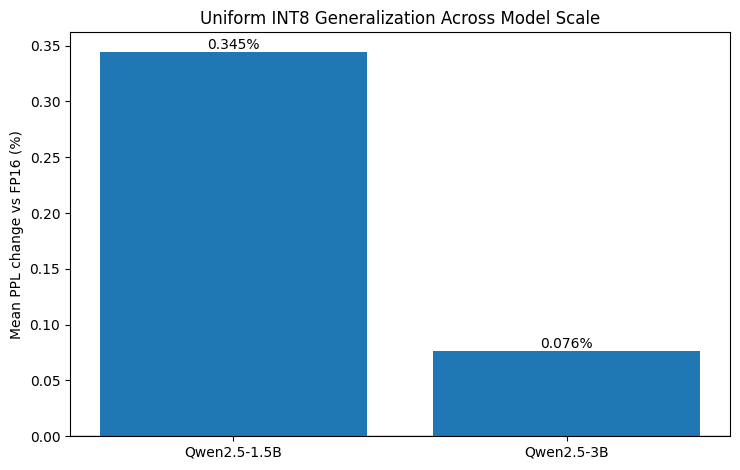

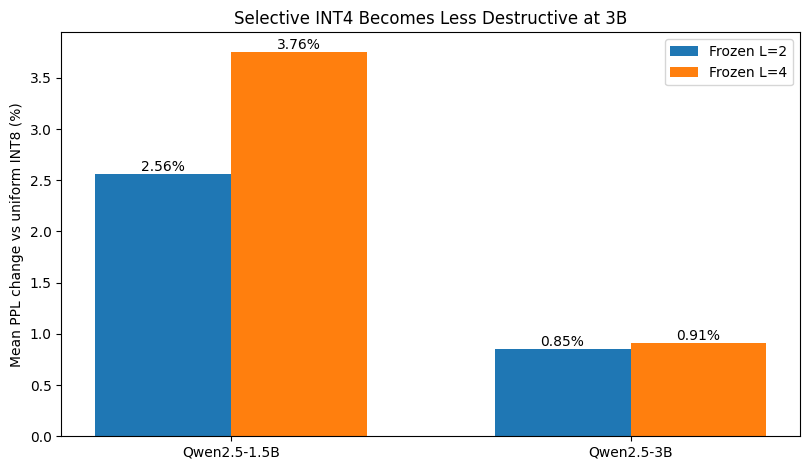

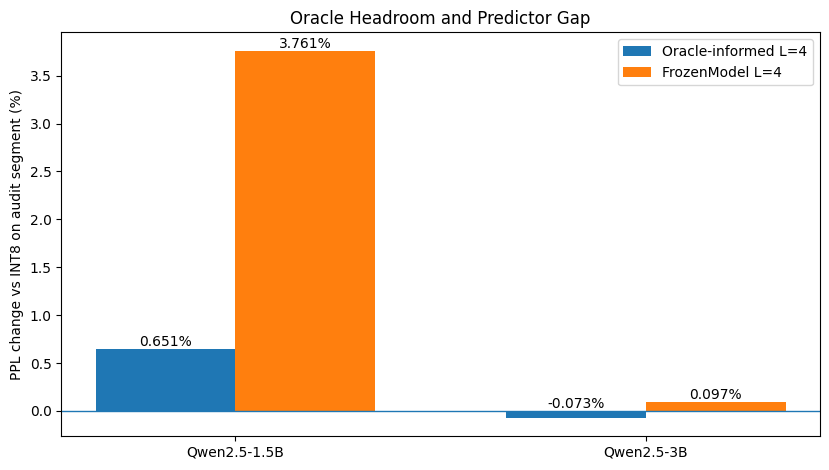


Cross-model change in selective-INT4 damage
-------------------------------------------
Frozen L=2 mean penalty reduction: 66.61%
Frozen L=4 mean penalty reduction: 75.65%


# Notebook 09 — Final Cross-Model Conclusion

## Purpose

Notebook 09 tested whether the conclusions obtained with
Qwen2.5-1.5B were specific to the relatively small development model.

The validation used Qwen2.5-3B while keeping the experimental protocol
fixed: WikiText-2, 2048-token cache, 16-token pages, a 32-token decision
delay, candidate Pages 6-120, per-vector INT4, L=2/L=4 budgets, the same
five unseen token windows, and the same StandardScaler + Ridge(alpha=1)
risk-prediction methodology.

No post-hoc feature engineering or policy tuning was performed.

## Uniform INT8

Uniform INT8 is the strongest result across both model sizes.

### Qwen2.5-1.5B

- FP16 analytical KV memory: 56.000 MiB
- INT8 analytical KV memory: 28.027 MiB
- analytical memory reduction: 49.951%
- mean unseen PPL change vs FP16: +0.3

In [9]:
# ============================================================
# Notebook 09 — CROSS-MODEL VALIDATION
# Cell 8:
#
# FINAL CONSOLIDATION
#
# Produce:
#   - 1.5B vs 3B headline table
#   - cross-model figures
#   - final scientific conclusion
#   - final markdown / JSON
#   - complete Notebook 09 ZIP
#
# NO MORE EXPERIMENTS AFTER THIS CELL.
# ============================================================

from pathlib import Path
import json
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Final output directories
# ============================================================

FINAL_DIR = (
    NB9_WORK_DIR
    / "final"
)

FIGURE_DIR = (
    FINAL_DIR
    / "figures"
)

FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 2. Frozen 1.5B final values from Notebook 08
#
# These are the FINAL corrected Notebook 08 numbers.
# ============================================================

MODEL_1P5B = {

    "Model":
        "Qwen2.5-1.5B",

    "Parameters_B":
        1.543714304,

    "FP16_Memory_MiB":
        56.000000,

    "INT8_Memory_MiB":
        28.027344,

    "INT8_Saving_vs_FP16_pct":
        49.951172,

    "INT8_Unseen_Mean_PPL_vs_FP16_pct":
        0.344610,

    "INT8_Unseen_Worst_PPL_vs_FP16_pct":
        0.896979,

    "Frozen_L2_Memory_MiB":
        27.821838,

    "Frozen_L2_Extra_Saving_vs_INT8_pct":
        0.733232,

    "Frozen_L2_Mean_PPL_vs_INT8_pct":
        2.556528,

    "Frozen_L2_Worst_PPL_vs_INT8_pct":
        4.171157,

    "Frozen_L4_Memory_MiB":
        27.616333,

    "Frozen_L4_Extra_Saving_vs_INT8_pct":
        1.466463,

    "Frozen_L4_Mean_PPL_vs_INT8_pct":
        3.756471,

    "Frozen_L4_Worst_PPL_vs_INT8_pct":
        5.490275,

    "Horizon_L2_Mean_PPL_vs_INT8_pct":
        2.150191,

    "Horizon_L4_Mean_PPL_vs_INT8_pct":
        3.265172,

    "Oracle_L2_Audit_PPL_vs_INT8_pct":
        0.039723,

    "Oracle_L4_Audit_PPL_vs_INT8_pct":
        0.651351,

    "Frozen_L2_Audit_PPL_vs_INT8_pct":
        3.629882,

    "Frozen_L4_Audit_PPL_vs_INT8_pct":
        3.761051,

    "Audit_Predicted_Total_Risk_Rho":
        0.589418,

    "Audit_V_NRMSE_Normalized_Risk_Rho":
        -0.099819,
}


# ============================================================
# 3. Extract final 3B values from measured results
# ============================================================

def get_agg_3b(
    method,
    L,
    column,
):

    row = aggregate_unseen_3b_df[

        (
            aggregate_unseen_3b_df[
                "Method"
            ]
            == method
        )

        &

        (
            aggregate_unseen_3b_df[
                "INT4_Budget"
            ]
            == L
        )
    ]

    assert len(row) == 1

    return float(
        row.iloc[0][
            column
        ]
    )


def get_audit_3b(
    method,
    L,
    column,
):

    row = audit_comparison_3b_df[

        (
            audit_comparison_3b_df[
                "Method"
            ]
            == method
        )

        &

        (
            audit_comparison_3b_df[
                "INT4_Budget"
            ]
            == L
        )
    ]

    assert len(row) == 1

    return float(
        row.iloc[0][
            column
        ]
    )


MODEL_3B = {

    "Model":
        "Qwen2.5-3B",

    "Parameters_B":
        PARAM_COUNT / 1e9,

    "FP16_Memory_MiB":
        ALL_FP16_MEMORY_MIB,

    "INT8_Memory_MiB":
        UNIFORM_INT8_MEMORY_MIB,

    "INT8_Saving_vs_FP16_pct":

        100.0 * (
            1.0
            - UNIFORM_INT8_MEMORY_MIB
            / ALL_FP16_MEMORY_MIB
        ),

    "INT8_Unseen_Mean_PPL_vs_FP16_pct":
        int8_mean_penalty_vs_fp16,

    "INT8_Unseen_Worst_PPL_vs_FP16_pct":
        int8_worst_penalty_vs_fp16,

    "Frozen_L2_Memory_MiB":
        final_policy_memory_mib(2),

    "Frozen_L2_Extra_Saving_vs_INT8_pct":

        100.0 * (
            1.0
            - final_policy_memory_mib(2)
            / UNIFORM_INT8_MEMORY_MIB
        ),

    "Frozen_L2_Mean_PPL_vs_INT8_pct":
        get_agg_3b(
            "FrozenModel",
            2,
            "Mean_Relative_PPL_vs_INT8_pct",
        ),

    "Frozen_L2_Worst_PPL_vs_INT8_pct":
        get_agg_3b(
            "FrozenModel",
            2,
            "Worst_Relative_PPL_vs_INT8_pct",
        ),

    "Frozen_L4_Memory_MiB":
        final_policy_memory_mib(4),

    "Frozen_L4_Extra_Saving_vs_INT8_pct":

        100.0 * (
            1.0
            - final_policy_memory_mib(4)
            / UNIFORM_INT8_MEMORY_MIB
        ),

    "Frozen_L4_Mean_PPL_vs_INT8_pct":
        get_agg_3b(
            "FrozenModel",
            4,
            "Mean_Relative_PPL_vs_INT8_pct",
        ),

    "Frozen_L4_Worst_PPL_vs_INT8_pct":
        get_agg_3b(
            "FrozenModel",
            4,
            "Worst_Relative_PPL_vs_INT8_pct",
        ),

    "Horizon_L2_Mean_PPL_vs_INT8_pct":
        get_agg_3b(
            "HorizonOnly",
            2,
            "Mean_Relative_PPL_vs_INT8_pct",
        ),

    "Horizon_L4_Mean_PPL_vs_INT8_pct":
        get_agg_3b(
            "HorizonOnly",
            4,
            "Mean_Relative_PPL_vs_INT8_pct",
        ),

    "Oracle_L2_Audit_PPL_vs_INT8_pct":
        get_audit_3b(
            "OracleLifetime",
            2,
            "Relative_PPL_vs_INT8_pct",
        ),

    "Oracle_L4_Audit_PPL_vs_INT8_pct":
        get_audit_3b(
            "OracleLifetime",
            4,
            "Relative_PPL_vs_INT8_pct",
        ),

    "Frozen_L2_Audit_PPL_vs_INT8_pct":
        get_audit_3b(
            "FrozenModel",
            2,
            "Relative_PPL_vs_INT8_pct",
        ),

    "Frozen_L4_Audit_PPL_vs_INT8_pct":
        get_audit_3b(
            "FrozenModel",
            4,
            "Relative_PPL_vs_INT8_pct",
        ),

    "Audit_Predicted_Total_Risk_Rho":
        float(
            rho_pred_total
        ),

    "Audit_V_NRMSE_Normalized_Risk_Rho":
        float(
            rho_vnorm_normalized
        ),
}


# ============================================================
# 4. Cross-model headline table
# ============================================================

cross_model_headline_df = pd.DataFrame(
    [
        MODEL_1P5B,
        MODEL_3B,
    ]
)


HEADLINE_PATH = (
    FINAL_DIR
    / "cross_model_headline_results.csv"
)


cross_model_headline_df.to_csv(
    HEADLINE_PATH,
    index=False,
)


print(
    "Cross-model headline results"
)

print(
    "----------------------------"
)


display(
    cross_model_headline_df
)


# ============================================================
# 5. Compact practical comparison table
# ============================================================

practical_rows = []


for model_info in [
    MODEL_1P5B,
    MODEL_3B,
]:

    model_name = model_info[
        "Model"
    ]


    practical_rows.extend([

        {
            "Model":
                model_name,

            "Method":
                "Uniform INT8",

            "Memory_MiB":
                model_info[
                    "INT8_Memory_MiB"
                ],

            "Saving_vs_FP16_pct":
                model_info[
                    "INT8_Saving_vs_FP16_pct"
                ],

            "Extra_Saving_vs_INT8_pct":
                0.0,

            "Mean_PPL_Penalty_pct":
                model_info[
                    "INT8_Unseen_Mean_PPL_vs_FP16_pct"
                ],

            "Penalty_Baseline":
                "FP16",
        },

        {
            "Model":
                model_name,

            "Method":
                "Frozen L=2",

            "Memory_MiB":
                model_info[
                    "Frozen_L2_Memory_MiB"
                ],

            "Saving_vs_FP16_pct":

                100.0 * (
                    1.0
                    - model_info[
                        "Frozen_L2_Memory_MiB"
                    ]
                    / model_info[
                        "FP16_Memory_MiB"
                    ]
                ),

            "Extra_Saving_vs_INT8_pct":
                model_info[
                    "Frozen_L2_Extra_Saving_vs_INT8_pct"
                ],

            "Mean_PPL_Penalty_pct":
                model_info[
                    "Frozen_L2_Mean_PPL_vs_INT8_pct"
                ],

            "Penalty_Baseline":
                "INT8",
        },

        {
            "Model":
                model_name,

            "Method":
                "Frozen L=4",

            "Memory_MiB":
                model_info[
                    "Frozen_L4_Memory_MiB"
                ],

            "Saving_vs_FP16_pct":

                100.0 * (
                    1.0
                    - model_info[
                        "Frozen_L4_Memory_MiB"
                    ]
                    / model_info[
                        "FP16_Memory_MiB"
                    ]
                ),

            "Extra_Saving_vs_INT8_pct":
                model_info[
                    "Frozen_L4_Extra_Saving_vs_INT8_pct"
                ],

            "Mean_PPL_Penalty_pct":
                model_info[
                    "Frozen_L4_Mean_PPL_vs_INT8_pct"
                ],

            "Penalty_Baseline":
                "INT8",
        },
    ])


practical_cross_model_df = (
    pd.DataFrame(
        practical_rows
    )
)


PRACTICAL_PATH = (
    FINAL_DIR
    / "cross_model_practical_summary.csv"
)


practical_cross_model_df.to_csv(
    PRACTICAL_PATH,
    index=False,
)


print()
print(
    "Practical cross-model summary"
)

print(
    "-----------------------------"
)


display(
    practical_cross_model_df
)


# ============================================================
# 6. Figure 1:
# Uniform INT8 unseen PPL penalty
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.5, 4.8)
)


models = [
    "Qwen2.5-1.5B",
    "Qwen2.5-3B",
]


int8_penalties = [
    MODEL_1P5B[
        "INT8_Unseen_Mean_PPL_vs_FP16_pct"
    ],
    MODEL_3B[
        "INT8_Unseen_Mean_PPL_vs_FP16_pct"
    ],
]


bars = ax.bar(
    models,
    int8_penalties,
)


ax.set_ylabel(
    "Mean PPL change vs FP16 (%)"
)

ax.set_title(
    "Uniform INT8 Generalization Across Model Scale"
)

ax.axhline(
    0,
    linewidth=1,
)


for bar, value in zip(
    bars,
    int8_penalties,
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,

        value,

        f"{value:.3f}%",

        ha="center",
        va="bottom",
    )


fig.tight_layout()


FIG_INT8_PATH = (
    FIGURE_DIR
    / "cross_model_uniform_int8.png"
)


fig.savefig(
    FIG_INT8_PATH,
    dpi=220,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# ============================================================
# 7. Figure 2:
# Frozen selective INT4 comparison
# ============================================================

fig, ax = plt.subplots(
    figsize=(8.2, 4.8)
)


x = np.arange(2)

width = 0.34


l2_values = [
    MODEL_1P5B[
        "Frozen_L2_Mean_PPL_vs_INT8_pct"
    ],
    MODEL_3B[
        "Frozen_L2_Mean_PPL_vs_INT8_pct"
    ],
]


l4_values = [
    MODEL_1P5B[
        "Frozen_L4_Mean_PPL_vs_INT8_pct"
    ],
    MODEL_3B[
        "Frozen_L4_Mean_PPL_vs_INT8_pct"
    ],
]


bars1 = ax.bar(
    x - width / 2,
    l2_values,
    width,
    label="Frozen L=2",
)


bars2 = ax.bar(
    x + width / 2,
    l4_values,
    width,
    label="Frozen L=4",
)


ax.set_xticks(
    x,
    models,
)

ax.set_ylabel(
    "Mean PPL change vs uniform INT8 (%)"
)

ax.set_title(
    "Selective INT4 Becomes Less Destructive at 3B"
)

ax.legend()


for bars in [
    bars1,
    bars2,
]:

    for bar in bars:

        value = bar.get_height()

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,

            value,

            f"{value:.2f}%",

            ha="center",
            va="bottom",
        )


fig.tight_layout()


FIG_INT4_PATH = (
    FIGURE_DIR
    / "cross_model_selective_int4.png"
)


fig.savefig(
    FIG_INT4_PATH,
    dpi=220,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# ============================================================
# 8. Figure 3:
# Oracle vs frozen on fixed audit segment
#
# Small negative 3B oracle values are plotted as measured,
# but the caption/conclusion explicitly treats them as
# approximately zero finite-sample effects.
# ============================================================

fig, ax = plt.subplots(
    figsize=(8.4, 4.8)
)


x = np.arange(2)

width = 0.34


oracle_values = [
    MODEL_1P5B[
        "Oracle_L4_Audit_PPL_vs_INT8_pct"
    ],
    MODEL_3B[
        "Oracle_L4_Audit_PPL_vs_INT8_pct"
    ],
]


frozen_values = [
    MODEL_1P5B[
        "Frozen_L4_Audit_PPL_vs_INT8_pct"
    ],
    MODEL_3B[
        "Frozen_L4_Audit_PPL_vs_INT8_pct"
    ],
]


bars1 = ax.bar(
    x - width / 2,
    oracle_values,
    width,
    label="Oracle-informed L=4",
)


bars2 = ax.bar(
    x + width / 2,
    frozen_values,
    width,
    label="FrozenModel L=4",
)


ax.set_xticks(
    x,
    models,
)

ax.set_ylabel(
    "PPL change vs INT8 on audit segment (%)"
)

ax.set_title(
    "Oracle Headroom and Predictor Gap"
)

ax.axhline(
    0,
    linewidth=1,
)

ax.legend()


for bars in [
    bars1,
    bars2,
]:

    for bar in bars:

        value = bar.get_height()

        y_pos = (
            value
            if value >= 0
            else 0
        )

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,

            y_pos,

            f"{value:.3f}%",

            ha="center",
            va="bottom",
        )


fig.tight_layout()


FIG_ORACLE_PATH = (
    FIGURE_DIR
    / "cross_model_oracle_gap.png"
)


fig.savefig(
    FIG_ORACLE_PATH,
    dpi=220,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# ============================================================
# 9. Quantitative cross-model changes
# ============================================================

frozen_l2_reduction_pct = (

    100.0

    * (
        1.0
        - MODEL_3B[
            "Frozen_L2_Mean_PPL_vs_INT8_pct"
        ]
        / MODEL_1P5B[
            "Frozen_L2_Mean_PPL_vs_INT8_pct"
        ]
    )
)


frozen_l4_reduction_pct = (

    100.0

    * (
        1.0
        - MODEL_3B[
            "Frozen_L4_Mean_PPL_vs_INT8_pct"
        ]
        / MODEL_1P5B[
            "Frozen_L4_Mean_PPL_vs_INT8_pct"
        ]
    )
)


print()
print(
    "Cross-model change in selective-INT4 damage"
)

print(
    "-------------------------------------------"
)


print(
    f"Frozen L=2 mean penalty reduction: "
    f"{frozen_l2_reduction_pct:.2f}%"
)

print(
    f"Frozen L=4 mean penalty reduction: "
    f"{frozen_l4_reduction_pct:.2f}%"
)


# ============================================================
# 10. Final scientific conclusion
# ============================================================

final_conclusion = f"""
# Notebook 09 — Final Cross-Model Conclusion

## Purpose

Notebook 09 tested whether the conclusions obtained with
Qwen2.5-1.5B were specific to the relatively small development model.

The validation used Qwen2.5-3B while keeping the experimental protocol
fixed: WikiText-2, 2048-token cache, 16-token pages, a 32-token decision
delay, candidate Pages 6-120, per-vector INT4, L=2/L=4 budgets, the same
five unseen token windows, and the same StandardScaler + Ridge(alpha=1)
risk-prediction methodology.

No post-hoc feature engineering or policy tuning was performed.

## Uniform INT8

Uniform INT8 is the strongest result across both model sizes.

### Qwen2.5-1.5B

- FP16 analytical KV memory: 56.000 MiB
- INT8 analytical KV memory: 28.027 MiB
- analytical memory reduction: 49.951%
- mean unseen PPL change vs FP16: +0.345%
- worst unseen PPL change: +0.897%

### Qwen2.5-3B

- FP16 analytical KV memory: 72.000 MiB
- INT8 analytical KV memory: 36.035 MiB
- analytical memory reduction: 49.951%
- mean unseen PPL change vs FP16: +{MODEL_3B["INT8_Unseen_Mean_PPL_vs_FP16_pct"]:.3f}%
- worst unseen PPL change: +{MODEL_3B["INT8_Unseen_Worst_PPL_vs_FP16_pct"]:.3f}%

Therefore the approximately 50% analytical KV-memory reduction from
uniform INT8 transfers cleanly from 1.5B to 3B with very small
perplexity degradation.

## Selective INT4 and model scale

The main new result is that selective INT4 is substantially less
destructive on Qwen2.5-3B.

FrozenModel mean PPL penalties versus INT8:

- 1.5B L=2: +2.557%
- 3B  L=2: +{MODEL_3B["Frozen_L2_Mean_PPL_vs_INT8_pct"]:.3f}%

- 1.5B L=4: +3.756%
- 3B  L=4: +{MODEL_3B["Frozen_L4_Mean_PPL_vs_INT8_pct"]:.3f}%

Thus the severe selective-INT4 degradation observed at 1.5B is not
universal. Model scale materially changes robustness to aggressive
KV-cache quantization in this experiment.

However, this does not validate the learned page selector.

On the five 3B unseen segments:

- Frozen L=2 mean penalty: +{MODEL_3B["Frozen_L2_Mean_PPL_vs_INT8_pct"]:.3f}%
- Horizon L=2 mean penalty: +{MODEL_3B["Horizon_L2_Mean_PPL_vs_INT8_pct"]:.3f}%

- Frozen L=4 mean penalty: +{MODEL_3B["Frozen_L4_Mean_PPL_vs_INT8_pct"]:.3f}%
- Horizon L=4 mean penalty: +{MODEL_3B["Horizon_L4_Mean_PPL_vs_INT8_pct"]:.3f}%

The learned method is therefore not consistently superior to the
simple remaining-lifetime baseline.

## Oracle audit

The fixed Unseen_3 lifetime-oracle audit again shows that page
sensitivity is highly heterogeneous.

For Qwen2.5-3B:

- Frozen L=2 audit penalty: +{MODEL_3B["Frozen_L2_Audit_PPL_vs_INT8_pct"]:.3f}%
- Oracle-informed L=2: {MODEL_3B["Oracle_L2_Audit_PPL_vs_INT8_pct"]:+.3f}%

- Frozen L=4 audit penalty: +{MODEL_3B["Frozen_L4_Audit_PPL_vs_INT8_pct"]:.3f}%
- Oracle-informed L=4: {MODEL_3B["Oracle_L4_Audit_PPL_vs_INT8_pct"]:+.3f}%

The small negative oracle values are interpreted as approximately zero
finite-sample effects, not as evidence that INT4 improves the model.

The 3B oracle gap is much smaller than the corresponding 1.5B gap,
which indicates that the larger model is substantially more forgiving
even when page selection is imperfect.

## Predictor interpretation

The basic quantization-distortion feature remains weak.

On the 3B unseen oracle audit:

- frozen predicted total risk vs true total risk:
  rho = {MODEL_3B["Audit_Predicted_Total_Risk_Rho"]:.3f}

- V_NRMSE_Max vs normalized intrinsic lifetime risk:
  rho = {MODEL_3B["Audit_V_NRMSE_Normalized_Risk_Rho"]:.3f}

Therefore V_NRMSE_Max should not be presented as a validated intrinsic
page-sensitivity estimator.

## Final project conclusion after cross-model validation

The cross-model experiment changes the interpretation of the original
negative result.

The small 1.5B model was partly responsible for the severe degradation
from selective INT4: Qwen2.5-3B is substantially more tolerant to the
same low-bit policy.

However, the learned online page-risk predictor remains inconsistent
and is not robustly better than a simple horizon-based baseline.

The strongest practical recommendation therefore remains:

**Uniform INT8 KV-cache quantization.**

Across both tested Qwen2.5 model sizes, it approximately halves
analytical KV-cache memory while preserving model quality extremely
well.

Selective INT4 remains promising because:

1. page sensitivity is strongly heterogeneous;
2. the larger model is substantially more robust to selective INT4;
3. oracle-informed page selection achieves approximately zero
   degradation on the 3B audit segment.

Future work should therefore focus on more transferable causal
sensitivity estimators and stronger low-bit quantizers rather than
assuming that recency, attention, confidence, or reconstruction error
alone identifies the safest pages.

## Implementation limitation

All low-bit memory values are analytical packed-cache estimates.

The experimental prototype quantizes and then dequantizes KV values
back into the standard FP16 DynamicCache for model-quality evaluation.
It does not implement a physical packed INT8/INT4 GPU cache or custom
low-bit attention kernels.

Therefore no runtime, bandwidth, physical GPU-memory, or tokens/sec
speedup is claimed.
"""


SUMMARY_MD_PATH = (
    FINAL_DIR
    / "notebook09_final_summary.md"
)


with open(
    SUMMARY_MD_PATH,
    "w",
    encoding="utf-8",
) as f:

    f.write(
        final_conclusion
    )


print()
print(
    final_conclusion
)


# ============================================================
# 11. Final JSON summary
# ============================================================

final_json = {

    "experiment":
        "Qwen2.5 cross-model KV-cache validation",

    "models": {

        "Qwen2.5-1.5B":
            MODEL_1P5B,

        "Qwen2.5-3B":
            MODEL_3B,
    },

    "cross_model_interpretation": {

        "uniform_int8_transfers":
            True,

        "selective_int4_less_destructive_at_3b":
            True,

        "learned_predictor_consistently_beats_horizon":
            False,

        "page_sensitivity_remains_heterogeneous":
            True,

        "oracle_headroom_remains":
            True,

        "final_practical_recommendation":
            "Uniform INT8",
    },

    "limitations": [

        "Only two models from the same Qwen2.5 family were tested.",

        "Cross-model transfer is across model scale, not across model families.",

        "WikiText-2 and 2048-token cache windows remain the primary benchmark.",

        "Low-bit memory is analytical packed-cache memory.",

        "The runtime prototype stores dequantized values in FP16 DynamicCache.",

        "No physical low-bit GPU memory or speedup claim is made.",

        "The oracle audit uses one frozen unseen segment per model.",

        "OracleLifetime is independent single-page ranking followed by joint evaluation, not a global subset optimum.",
    ],
}


FINAL_JSON_PATH = (
    FINAL_DIR
    / "notebook09_final_conclusion.json"
)


with open(
    FINAL_JSON_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        final_json,
        f,
        indent=2,
    )


# ============================================================
# 12. Copy the most important detailed tables to final/
# ============================================================

important_tables = {

    "qwen3b_unseen_quality_results.csv":
        unseen_quality_3b_df,

    "qwen3b_unseen_aggregate_results.csv":
        aggregate_unseen_3b_df,

    "qwen3b_unseen3_oracle_comparison.csv":
        audit_comparison_3b_df,

    "qwen3b_unseen3_predictor_oracle_gap.csv":
        oracle_gap_3b_df,

    "qwen3b_int8_vs_fp16_unseen.csv":
        int8_unseen_df,

    "cross_model_headline_results.csv":
        cross_model_headline_df,

    "cross_model_practical_summary.csv":
        practical_cross_model_df,
}


for filename, dataframe in (
    important_tables.items()
):

    dataframe.to_csv(
        FINAL_DIR / filename,
        index=False,
    )


# ============================================================
# 13. Create complete Notebook 09 ZIP
# ============================================================

ZIP_BASE = (
    "notebook09_final_results"
)


zip_path_str = shutil.make_archive(

    ZIP_BASE,

    "zip",

    root_dir=str(
        NB9_WORK_DIR
    ),
)


ZIP_PATH = Path(
    zip_path_str
)


# ============================================================
# 14. Final file inventory
# ============================================================

final_files = sorted(

    p.relative_to(
        NB9_WORK_DIR
    )

    for p in NB9_WORK_DIR.rglob("*")

    if p.is_file()
)


print()
print(
    "=================================================="
)

print(
    "NOTEBOOK 09 FINAL ARTIFACTS"
)

print(
    "=================================================="
)


for p in final_files:

    print(
        p
    )


print()
print(
    "=================================================="
)

print(
    "FINAL NOTEBOOK 09 CONCLUSION"
)

print(
    "=================================================="
)


print(
    "Uniform INT8 remains the strongest practical policy."
)

print(
    f"3B uniform INT8: "
    f"{UNIFORM_INT8_MEMORY_MIB:.3f} MiB "
    f"({100.0 * (1.0 - UNIFORM_INT8_MEMORY_MIB / ALL_FP16_MEMORY_MIB):.3f}% "
    f"saving vs FP16), "
    f"mean unseen PPL change "
    f"{int8_mean_penalty_vs_fp16:+.3f}%."
)


print()
print(
    "Selective INT4 is substantially less destructive "
    "on 3B than on 1.5B."
)

print(

    f"Frozen L=2: "
    f"1.5B +2.557% -> "
    f"3B +{MODEL_3B['Frozen_L2_Mean_PPL_vs_INT8_pct']:.3f}%"
)

print(

    f"Frozen L=4: "
    f"1.5B +3.756% -> "
    f"3B +{MODEL_3B['Frozen_L4_Mean_PPL_vs_INT8_pct']:.3f}%"
)


print()
print(
    "But the learned predictor is still not consistently "
    "better than HorizonOnly."
)

print(
    "Therefore model scale explains part of the original "
    "failure, while reliable online page selection remains "
    "an open problem."
)


print()
print(
    f"Final summary: "
    f"{SUMMARY_MD_PATH}"
)

print(
    f"Final JSON:    "
    f"{FINAL_JSON_PATH}"
)

print(
    f"Final ZIP:     "
    f"{ZIP_PATH}"
)

print()
print(
    "Notebook 09 experimental work is COMPLETE."
)

print(
    "There will be NO Notebook 10."
)

print(
    "Next step: update the final research article and references."
)

In [10]:
# ============================================================
# Notebook 09 — Download Final Results
# ============================================================

from pathlib import Path
import shutil
from google.colab import files


NB9_DIR = Path("notebook09_results")
ZIP_PATH = Path("notebook09_final_results.zip")


# Rebuild ZIP if it does not already exist
if not ZIP_PATH.exists():

    if not NB9_DIR.exists():
        raise FileNotFoundError(
            "notebook09_results directory was not found."
        )

    shutil.make_archive(
        "notebook09_final_results",
        "zip",
        root_dir=str(NB9_DIR),
    )


print(
    f"ZIP ready: {ZIP_PATH}"
)

print(
    f"Size: {ZIP_PATH.stat().st_size / 1024:.1f} KiB"
)

files.download(
    str(ZIP_PATH)
)

ZIP ready: notebook09_final_results.zip
Size: 282.4 KiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>